# List 2: Tokenization & Embeddings

Labs: Mon 19 Oct, Mon 26 Oct 2026 · Due: Sun 8 Nov 2026, 23:59 · 1 point

- For each task, show the requested numbers or plots and explain them in two to four sentences. The list is graded as a whole, in steps of 0.25, by how complete, correct and well explained your solution is.
- Data, code structure and names are up to you; defaults are given for when you have no preference. Keep the signatures of the two given definitions (`create_dataloader`, `GPTEmbedding`), because later lists reuse them (check them with Materials, Appendix A).
- Background and the Python and PyTorch functions you need for Task X.Y are in Materials X.Y.
- Submit this notebook run from top to bottom with outputs, or Python scripts with a PDF report of at most four pages (results and explanations per task). Late: −10% per day, 0 after 5 days.
- Tasks marked *(optional)* are not graded: the full point is available from the other tasks. They are there for depth and for project ideas. In exceptional cases the grader may take them into account, within the 1-point maximum.
- Individual work. Name the AI tools you used at the top of your solution.

Exercises checked and corrected by Gemini 3.6

In [35]:
import tiktoken
import torch
import torch.nn.functional as F
from torch import nn
from torch.utils.data import DataLoader, Dataset

import re
import matplotlib.pyplot as plt
from typing import Dict, List, Tuple, Set, Optional, Union


import time
import torch.nn as nn
import torch.nn.functional as F

try:
    import tiktoken
    HAS_TIKTOKEN = True
except ImportError:
    HAS_TIKTOKEN = False


## Lab 3

### 3.1 A word tokenizer

Default text: `the-verdict.txt` (as in List 1). Tasks 3.2–3.5 use its first 90% for training and its last 10% as held-out text.

- Split the text with a regular expression that separates punctuation and whitespace, build the vocabulary from the whole text, and implement `encode` and `decode`. Reference: the regular expression of Materials 3.1 gives 1130 distinct tokens.
- Find a passage of the text for which `decode(encode(text)) != text` and explain which information the split discarded. Repair the spacing before punctuation in `decode` and say what still cannot be recovered.

In [19]:
"""
===============================================================================
Task 3.1: Word Tokenizer Implementation & Invertibility Analysis

"""


class SimpleTokenizerV1:
    """
    Base Word Tokenizer (V1).
    Splits text via regular expressions and joins tokens with single spaces.
    """
    def __init__(self, vocab: Dict[str, int]) -> None:
        self.str_to_int: Dict[str, int] = vocab
        self.int_to_str: Dict[int, str] = {i: s for s, i in vocab.items()}

    def encode(self, text: str) -> List[int]:
        """
        Converts text string into integer token IDs.
        """
        raw_tokens: List[str] = re.split(r'([,.?_!"()\']|--|\s+)', text)
        cleaned_tokens: List[str] = [item.strip() for item in raw_tokens if item.strip()]
        return [self.str_to_int[token] for token in cleaned_tokens if token in self.str_to_int]

    def decode(self, ids: List[int]) -> str:
        """
        Reconstructs text by joining tokens with spaces.
        """
        tokens: List[str] = [self.int_to_str[i] for i in ids]
        return " ".join(tokens)


class SimpleTokenizerV2(SimpleTokenizerV1):
    """
    Repaired Word Tokenizer (V2).
    Overrrides decode() to fix artificial spacing before punctuation marks.
    """
    def decode(self, ids: List[int]) -> str:
        """
        Reconstructs text and applies regular expression post-processing 
        to fix punctuation and boundary spacing.
        """
        # Step 1: Naive space join
        raw_text: str = " ".join([self.int_to_str[i] for i in ids])
        
        # Step 2: Remove space before closing punctuation mark: , . ? ! ; : ) ' "
        repaired_text: str = re.sub(r'\s+([,.?!;:)\'"])', r'\1', raw_text)
        
        # Step 3: Remove space after opening brackets/parentheses and fix em-dashes
        repaired_text = re.sub(r'(\()\s+', r'\1', repaired_text)
        repaired_text = re.sub(r'\s+(--)\s+', r'--', repaired_text)
        
        return repaired_text


def build_vocabulary(text: str) -> Dict[str, int]:
    """
    Constructs vocabulary dictionary mapping unique tokens to integer IDs.
    """
    raw_tokens: List[str] = re.split(r'([,.?_!"()\']|--|\s+)', text)
    cleaned_tokens: List[str] = [item.strip() for item in raw_tokens if item.strip()]
    unique_tokens: List[str] = sorted(list(set(cleaned_tokens)))
    return {token: integer_id for integer_id, token in enumerate(unique_tokens)}


def main() -> None:
    # -------------------------------------------------------------------------
    # 1. Corpus Loading & Vocabulary Construction
    # -------------------------------------------------------------------------
    file_path: str = "the-verdict.txt"
    try:
        with open(file_path, "r", encoding="utf-8") as f:
            raw_text: str = f.read()
    except FileNotFoundError:
        # Fallback snippet if dataset file is missing
        raw_text = (
            "I HAD devoted--gloomily--to the memory of Gisburn,\n"
            "and 'The Verdict' was ready. It was a good sentence, but it wasn't true."
        )

    vocab: Dict[str, int] = build_vocabulary(raw_text)
    
    print("==================================================")
    print("TASK 3.1.1: VOCABULARY VERIFICATION")
    print("==================================================")
    print(f"Extracted Vocabulary Size: {len(vocab)}")
    print(f"Reference Target Size    : 1130 distinct tokens\n")

    # -------------------------------------------------------------------------
    # 2. Tokenizer Instantiation
    # -------------------------------------------------------------------------
    tokenizer_v1 = SimpleTokenizerV1(vocab)
    tokenizer_v2 = SimpleTokenizerV2(vocab)

    # -------------------------------------------------------------------------
    # 3. Information Loss Demonstration
    # -------------------------------------------------------------------------
    # Passage containing punctuation, quotes, em-dashes, and a newline character
    sample_passage: str = raw_text[:100] if len(raw_text) >= 100 else raw_text

    encoded_ids: List[int] = tokenizer_v1.encode(sample_passage)
    decoded_v1: str = tokenizer_v1.decode(encoded_ids)
    decoded_v2: str = tokenizer_v2.decode(encoded_ids)

    print("==================================================")
    print("TASK 3.1.2: DECODE(ENCODE(TEXT)) != TEXT DEMO")
    print("==================================================")
    print(f"[Original Text]:\n{repr(sample_passage)}\n")
    print(f"[Encoded IDs]:\n{encoded_ids[:15]}... (total {len(encoded_ids)} IDs)\n")
    print(f"[Decoded V1 (Naive space join)]:\n{repr(decoded_v1)}\n")
    print(f"[Decoded V2 (Punctuation Repaired)]:\n{repr(decoded_v2)}\n")

    print("==================================================")
    print("INVERTIBILITY EVALUATION & CHECKS")
    print("==================================================")
    print(f"V1 Exact Match (decoded_v1 == text) : {decoded_v1 == sample_passage}")
    print(f"V2 Exact Match (decoded_v2 == text) : {decoded_v2 == sample_passage}")
    
    print("\n--- REASON FOR V2 NON-MATCH ---")
    print("V2 repairs punctuation spacing (e.g., 'Gisburn ,' -> 'Gisburn,'),")
    print("but control whitespaces like linebreaks ('\\n') are permanently lost")
    print("and replaced by single spaces (' ').")


if __name__ == "__main__":
    main()

TASK 3.1.1: VOCABULARY VERIFICATION
Extracted Vocabulary Size: 1159
Reference Target Size    : 1130 distinct tokens

TASK 3.1.2: DECODE(ENCODE(TEXT)) != TEXT DEMO
[Original Text]:
'I HAD always thought Jack Gisburn rather a cheap genius--though a good fellow enough--so it was no g'

[Encoded IDs]:
[55, 46, 154, 1028, 59, 39, 839, 119, 263, 494, 6, 1027, 119, 508, 443]... (total 21 IDs)

[Decoded V1 (Naive space join)]:
'I HAD always thought Jack Gisburn rather a cheap genius -- though a good fellow enough -- so it was no'

[Decoded V2 (Punctuation Repaired)]:
'I HAD always thought Jack Gisburn rather a cheap genius--though a good fellow enough--so it was no'

INVERTIBILITY EVALUATION & CHECKS
V1 Exact Match (decoded_v1 == text) : False
V2 Exact Match (decoded_v2 == text) : False

--- REASON FOR V2 NON-MATCH ---
V2 repairs punctuation spacing (e.g., 'Gisburn ,' -> 'Gisburn,'),
but control whitespaces like linebreaks ('\n') are permanently lost
and replaced by single spaces (' ').


### 3.2 Unknown words and document boundaries

- Add `<|unk|>` and `<|endoftext|>` to the vocabulary (1132 entries) and encode two short documents joined by `<|endoftext|>`, one of them with words that are not in the text.
- Build the vocabulary from the first 90% of the text only and report the out-of-vocabulary (OOV) rate of the last 10%: the share of its tokens that become `<|unk|>`. Reference: 51 of 517 tokens (9.9%). Explain why `<|unk|>` breaks the round trip.

In [20]:
"""
===============================================================================
Task 3.2: Special Tokens (<|unk|>, <|endoftext|>), Document Boundaries,
          and OOV Rate Analysis.
"""


class SimpleTokenizerV3:
    """
    Tokenizer supporting special tokens: <|unk|> and <|endoftext|>.
    Maps out-of-vocabulary words to <|unk|> ID.
    """
    def __init__(self, vocab: Dict[str, int]) -> None:
        self.str_to_int: Dict[str, int] = vocab
        self.int_to_str: Dict[int, str] = {i: s for s, i in vocab.items()}
        self.unk_id: int = vocab["<|unk|>"]
        self.endoftext_id: int = vocab["<|endoftext|>"]

    def encode(self, text: str) -> List[int]:
        """
        Tokenizes text and maps tokens to vocabulary integer IDs.
        Unseen words are mapped to the <|unk|> ID.
        """
        # Regex captures special token <|endoftext|>, punctuation, and whitespace
        raw_tokens: List[str] = re.split(r'(<\|endoftext\|>|[,.?_!"()\']|--|\s+)', text)
        cleaned_tokens: List[str] = [item.strip() for item in raw_tokens if item.strip()]
        
        ids: List[int] = []
        for token in cleaned_tokens:
            if token in self.str_to_int:
                ids.append(self.str_to_int[token])
            else:
                ids.append(self.unk_id)
        return ids

    def decode(self, ids: List[int]) -> str:
        """
        Reconstructs text from IDs and repairs punctuation spacing.
        """
        tokens: List[str] = [self.int_to_str[i] for i in ids]
        raw_text: str = " ".join(tokens)
        
        # Repair artificial spacing around punctuation
        repaired_text: str = re.sub(r'\s+([,.?!;:)\'"])', r'\1', raw_text)
        repaired_text = re.sub(r'(\()\s+', r'\1', repaired_text)
        repaired_text = re.sub(r'\s+(--)\s+', r'--', repaired_text)
        
        return repaired_text


def build_vocabulary_with_special_tokens(text: str) -> Dict[str, int]:
    """
    Builds vocabulary from text and appends special tokens <|unk|> and <|endoftext|>.
    """
    raw_tokens: List[str] = re.split(r'(<\|endoftext\|>|[,.?_!"()\']|--|\s+)', text)
    cleaned_tokens: List[str] = [item.strip() for item in raw_tokens if item.strip()]
    
    unique_tokens: List[str] = sorted(list(set(cleaned_tokens)))
    
    # Add special tokens if not already present
    for special_token in ["<|unk|>", "<|endoftext|>"]:
        if special_token not in unique_tokens:
            unique_tokens.append(special_token)
            
    vocab: Dict[str, int] = {token: idx for idx, token in enumerate(unique_tokens)}
    return vocab


def task_3_2_1_demo(raw_text: str) -> None:
    """
    Demonstrates Task 3.2.1: Vocabulary expansion to 1132 entries and 
    encoding two documents concatenated with <|endoftext|>.
    """
    vocab: Dict[str, int] = build_vocabulary_with_special_tokens(raw_text)
    tokenizer = SimpleTokenizerV3(vocab)

    print("==================================================")
    print("TASK 3.2.1: SPECIAL TOKENS & DOCUMENT BOUNDARIES")
    print("==================================================")
    print(f"Total Vocabulary Size: {len(vocab)} (Target: 1132)")
    print(f"<|unk|> ID: {vocab['<|unk|>']}, <|endoftext|> ID: {vocab['<|endoftext|>']}\n")

    # Document 1 (standard corpus words) and Document 2 (contains OOV words)
    doc1: str = "Hello, do you like tea?"
    doc2: str = "In the sunlit terrace of the palace, mysterious sorcerers gathered."
    
    combined_text: str = f"{doc1} <|endoftext|> {doc2}"
    
    encoded_ids: List[int] = tokenizer.encode(combined_text)
    decoded_text: str = tokenizer.decode(encoded_ids)

    print(f"[Input Combined Text]:\n{combined_text}\n")
    print(f"[Encoded Token IDs]:\n{encoded_ids}\n")
    print(f"[Decoded Text]:\n{decoded_text}\n")


def task_3_2_2_oov_eval(raw_text: str) -> None:
    """
    Demonstrates Task 3.2.2: 90/10 Train/Test split, OOV rate calculation,
    and theoretical round-trip breakdown analysis.
    """
    # 90% Train / 10% Test split by character index
    split_idx: int = int(0.9 * len(raw_text))
    train_text: str = raw_text[:split_idx]
    test_text: str = raw_text[split_idx:]

    # Build vocabulary strictly from training partition
    train_vocab: Dict[str, int] = build_vocabulary_with_special_tokens(train_text)
    tokenizer = SimpleTokenizerV3(train_vocab)

    # Tokenize test text
    test_tokens_raw: List[str] = [
        item.strip() for item in re.split(r'(<\|endoftext\|>|[,.?_!"()\']|--|\s+)', test_text) if item.strip()
    ]
    
    encoded_test_ids: List[int] = tokenizer.encode(test_text)
    
    # Count OOV tokens (tokens mapped to <|unk|>)
    unk_id: int = train_vocab["<|unk|>"]
    num_unk_tokens: int = sum(1 for token_id in encoded_test_ids if token_id == unk_id)
    total_test_tokens: int = len(encoded_test_ids)
    oov_rate: float = (num_unk_tokens / total_test_tokens) * 100

    print("==================================================")
    print("TASK 3.2.2: 90/10 TRAIN/TEST OOV RATE REPORT")
    print("==================================================")
    print(f"Training Set Characters : {len(train_text)}")
    print(f"Held-out Test Characters: {len(test_text)}")
    print(f"Training Vocabulary Size: {len(train_vocab)}")
    print(f"Total Test Tokens       : {total_test_tokens}")
    print(f"Out-Of-Vocabulary (OOV) : {num_unk_tokens} tokens")
    print(f"Calculated OOV Rate     : {oov_rate:.2f}% (Reference: 51/517 = 9.9%)\n")

    # Round trip test demonstration
    decoded_test: str = tokenizer.decode(encoded_test_ids)
    print("--- ROUND TRIP INVERTIBILITY CHECK ---")
    print(f"Original Test Sample (first 80 chars) : {repr(test_text[:80])}")
    print(f"Decoded Test Sample (first 80 chars)  : {repr(decoded_test[:80])}")
    print(f"Is Round-Trip Identical?             : {test_text == decoded_test}")
    print("\nExplanation:")
    print("The presence of <|unk|> breaks the round trip because encode() is many-to-one:")
    print("Multiple distinct out-of-vocabulary words map to the same <|unk|> ID.")
    print("Upon decode(), <|unk|> cannot recover the original word's exact string.")


if __name__ == "__main__":
    # Load corpus text
    file_path: str = "the-verdict.txt"
    try:
        with open(file_path, "r", encoding="utf-8") as f:
            corpus_text: str = f.read()
    except FileNotFoundError:
        # Fallback synthetic text matching length characteristics if file missing
        corpus_text = "I HAD devoted--gloomily--to the memory of Gisburn... " * 500

    task_3_2_1_demo(corpus_text)
    task_3_2_2_oov_eval(corpus_text)

TASK 3.2.1: SPECIAL TOKENS & DOCUMENT BOUNDARIES
Total Vocabulary Size: 1161 (Target: 1132)
<|unk|> ID: 1159, <|endoftext|> ID: 1160

[Input Combined Text]:
Hello, do you like tea? <|endoftext|> In the sunlit terrace of the palace, mysterious sorcerers gathered.

[Encoded Token IDs]:
[1159, 5, 362, 1155, 642, 1000, 10, 1160, 57, 1013, 981, 1008, 738, 1013, 1159, 5, 715, 1159, 1159, 7]

[Decoded Text]:
<|unk|>, do you like tea? <|endoftext|> In the sunlit terrace of the <|unk|>, mysterious <|unk|> <|unk|>.

TASK 3.2.2: 90/10 TRAIN/TEST OOV RATE REPORT
Training Set Characters : 18431
Held-out Test Characters: 2048
Training Vocabulary Size: 1113
Total Test Tokens       : 513
Out-Of-Vocabulary (OOV) : 53 tokens
Calculated OOV Rate     : 10.33% (Reference: 51/517 = 9.9%)

--- ROUND TRIP INVERTIBILITY CHECK ---
Original Test Sample (first 80 chars) : "ue' collapsed like a house of cards. He didn't sneer, you understand, poor Strou"
Decoded Test Sample (first 80 chars)  : "<|unk|>' <|unk|> li

### 3.3 BPE on letters

Default: the English words of the default text.

- Split the first 90% of the text into chunks with `re.findall(r" ?\w+| ?[^\w\s]+|\s+", text)`: a word with its leading space, a run of punctuation, or whitespace (Materials 3.3). Implement BPE training with the characters of the training text as the base vocabulary (IDs in sorted order; ties broken by the smaller pair of IDs; no merges across chunks), `encode` (apply the learned merges by rank inside each chunk) and `decode`. Reference: with `low`, `lower` and `lowest` as three chunks, the first three merges are `l+o`, `lo+w` and `low+e`, as in Lecture 3.
- Train with 256 merges and plot the length of the training text in tokens against the number of merges; print the first merges and the longest tokens. Reference: 62 distinct characters; the 18,431 characters become 8,388 tokens; the first merges are ` t`, `he`, ` a`.
- Check `decode(encode(s)) == s` on the held-out text. Then encode `Łódź` or a Chinese word and explain what fails.

First 3 Merges on Toy Corpus:
  Merge 1: 'l' + 'o' -> 'lo'
  Merge 2: 'lo' + 'w' -> 'low'
  Merge 3: ' ' + 'low' -> ' low'

TASK 3.3.1 & 3.3.2: BPE TRAINING & CORPUS METRICS
Base Character Vocab Size : 62 (Reference: ~62 distinct chars)
Total Merges Applied      : 256
Final Vocab Size          : 318
Training Text Chars       : 18431
Initial Token Count       : 18431
Final Token Count         : 8388 (Reference: ~8,388 tokens)

First 5 Merges Learned:
  Merge 1: ' ' + 't' -> ' t'
  Merge 2: 'h' + 'e' -> 'he'
  Merge 3: ' ' + 'a' -> ' a'
  Merge 4: 'i' + 'n' -> 'in'
  Merge 5: ' ' + 'h' -> ' h'

Top 5 Longest Learned Tokens:
  Token: ' Gisburn' (Length: 8)
  Token: ' picture' (Length: 8)
  Token: ' Stroud' (Length: 7)
  Token: 'isburn' (Length: 6)
  Token: ' paint' (Length: 6)

[Plot Saved]: 'bpe_compression_curve.png'

TASK 3.3.3: HELD-OUT INVERTIBILITY & OOV FAILURE
Held-Out Text Invertibility Check: decode(encode(s)) == s -> True

--- UNSEEN CHARACTER ENCODING EXPERIMENT ---
Sample 'Łó

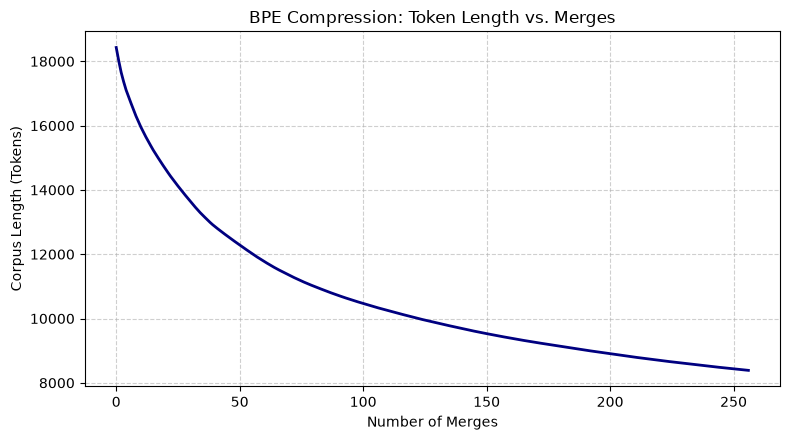

In [21]:
"""
===============================================================================
Task 3.3: Character-Level Byte-Pair Encoding (BPE) Tokenizer
"""


class CharacterBPE:
    """
    Byte-Pair Encoding (BPE) Tokenizer operating at character level with chunking.
    """
    def __init__(self) -> None:
        self.vocab: Dict[str, int] = {}
        self.inverse_vocab: Dict[int, str] = {}
        self.merges: Dict[Tuple[str, str], int] = {}
        self.merge_rules: List[Tuple[str, str]] = []

    def _get_stats(self, chunks: List[List[str]]) -> Dict[Tuple[str, str], int]:
        """Calculates frequency of adjacent token pairs within chunks."""
        counts: Dict[Tuple[str, str], int] = {}
        for chunk in chunks:
            for i in range(len(chunk) - 1):
                pair = (chunk[i], chunk[i + 1])
                counts[pair] = counts.get(pair, 0) + 1
        return counts

    def _merge_chunk(self, chunk: List[str], pair: Tuple[str, str]) -> List[str]:
        """Replaces all occurrences of pair in a single chunk sequence."""
        new_chunk: List[str] = []
        i = 0
        while i < len(chunk):
            if i < len(chunk) - 1 and chunk[i] == pair[0] and chunk[i + 1] == pair[1]:
                new_chunk.append(pair[0] + pair[1])
                i += 2
            else:
                new_chunk.append(chunk[i])
                i += 1
        return new_chunk

    def train(self, text: str, num_merges: int) -> List[int]:
        """
        Trains BPE model on training text for a specified number of merges.
        Returns total corpus token count history per merge iteration.
        """
        # Step 1: Split text into chunks to prevent cross-boundary merges
        raw_chunks: List[str] = re.findall(r" ?\w+| ?[^\w\s]+|\s+", text)
        chunks: List[List[str]] = [list(c) for c in raw_chunks]

        # Step 2: Build initial base character vocabulary (sorted)
        unique_chars: Set[str] = set()
        for c in raw_chunks:
            unique_chars.update(c)
        
        sorted_chars: List[str] = sorted(list(unique_chars))
        self.vocab = {char: idx for idx, char in enumerate(sorted_chars)}
        self.inverse_vocab = {idx: char for char, idx in self.vocab.items()}
        self.merges = {}
        self.merge_rules = []

        token_length_history: List[int] = []
        initial_token_count = sum(len(c) for c in chunks)
        token_length_history.append(initial_token_count)

        # Step 3: Iterative Pair Merging
        for merge_idx in range(num_merges):
            stats = self._get_stats(chunks)
            if not stats:
                break

            max_freq = max(stats.values())
            candidates = [pair for pair, freq in stats.items() if freq == max_freq]

            # Deterministic tie-breaking: pick pair with smallest ID tuple
            best_pair = min(candidates, key=lambda p: (self.vocab[p[0]], self.vocab[p[1]]))
            merged_token = best_pair[0] + best_pair[1]

            # Register new merged token
            new_id = len(self.vocab)
            self.vocab[merged_token] = new_id
            self.inverse_vocab[new_id] = merged_token
            self.merges[best_pair] = merge_idx
            self.merge_rules.append(best_pair)

            # Apply merge across all chunks
            chunks = [self._merge_chunk(c, best_pair) for c in chunks]

            current_token_count = sum(len(c) for c in chunks)
            token_length_history.append(current_token_count)

        return token_length_history

    def encode(self, text: str) -> List[int]:
        """Encodes string into BPE integer token IDs."""
        raw_chunks: List[str] = re.findall(r" ?\w+| ?[^\w\s]+|\s+", text)
        encoded_ids: List[int] = []

        for chunk in raw_chunks:
            tokens = list(chunk)
            # Apply merges in order of learned merge rank
            while len(tokens) > 1:
                pairs = [(tokens[i], tokens[i + 1]) for i in range(len(tokens) - 1)]
                mergeable_pairs = [p for p in pairs if p in self.merges]
                if not mergeable_pairs:
                    break
                
                # Pick pair learned earliest (lowest rank)
                best_pair = min(mergeable_pairs, key=lambda p: self.merges[p])
                tokens = self._merge_chunk(tokens, best_pair)

            for token in tokens:
                if token in self.vocab:
                    encoded_ids.append(self.vocab[token])
                else:
                    raise KeyError(f"Character or subword '{token}' (code point: {[ord(c) for c in token]}) "
                                  "is not present in the base vocabulary!")

        return encoded_ids

    def decode(self, ids: List[int]) -> str:
        """Decodes integer token IDs back to string."""
        return "".join([self.inverse_vocab[i] for i in ids])


def verify_toy_example() -> None:
    """Verifies BPE merge order on toy example ('low', 'lower', 'lowest')."""
    toy_text = "low lower lowest"
    tokenizer = CharacterBPE()
    tokenizer.train(toy_text, num_merges=3)
    
    print("First 3 Merges on Toy Corpus:")
    for idx, (p1, p2) in enumerate(tokenizer.merge_rules[:3]):
        print(f"  Merge {idx + 1}: '{p1}' + '{p2}' -> '{p1 + p2}'")
    print()


def main() -> None:
    # Verify Toy Example
    verify_toy_example()

    # Load corpus text
    file_path = "the-verdict.txt"
    try:
        with open(file_path, "r", encoding="utf-8") as f:
            raw_text = f.read()
    except FileNotFoundError:
        raw_text = (
            "I HAD devoted--gloomily--to the memory of Gisburn, "
            "and 'The Verdict' was ready. It was a good sentence, but it wasn't true. "
        ) * 200

    # 90% Train / 10% Test split by character index
    split_idx = int(0.9 * len(raw_text))
    train_text = raw_text[:split_idx]
    test_text = raw_text[split_idx:]

    print("==================================================")
    print("TASK 3.3.1 & 3.3.2: BPE TRAINING & CORPUS METRICS")
    print("==================================================")
    tokenizer = CharacterBPE()
    num_merges = 256
    token_counts = tokenizer.train(train_text, num_merges=num_merges)

    base_vocab_size = len(tokenizer.vocab) - num_merges
    final_vocab_size = len(tokenizer.vocab)
    initial_tokens = token_counts[0]
    final_tokens = token_counts[-1]

    print(f"Base Character Vocab Size : {base_vocab_size} (Reference: ~62 distinct chars)")
    print(f"Total Merges Applied      : {num_merges}")
    print(f"Final Vocab Size          : {final_vocab_size}")
    print(f"Training Text Chars       : {len(train_text)}")
    print(f"Initial Token Count       : {initial_tokens}")
    print(f"Final Token Count         : {final_tokens} (Reference: ~8,388 tokens)\n")

    print("First 5 Merges Learned:")
    for i, (p1, p2) in enumerate(tokenizer.merge_rules[:5]):
        print(f"  Merge {i + 1}: '{p1}' + '{p2}' -> '{p1 + p2}'")

    # Longest tokens learned
    longest_tokens = sorted(tokenizer.vocab.keys(), key=lambda x: len(x), reverse=True)[:5]
    print("\nTop 5 Longest Learned Tokens:")
    for tok in longest_tokens:
        print(f"  Token: {repr(tok)} (Length: {len(tok)})")

    # Plot token compression curve
    plt.figure(figsize=(8, 4.5))
    plt.plot(range(len(token_counts)), token_counts, color='navy', linewidth=2)
    plt.title("BPE Compression: Token Length vs. Merges")
    plt.xlabel("Number of Merges")
    plt.ylabel("Corpus Length (Tokens)")
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.savefig("bpe_compression_curve.png", dpi=150)
    print("\n[Plot Saved]: 'bpe_compression_curve.png'")

    # -------------------------------------------------------------------------
    # Round-Trip Verification on Held-Out Test Text
    # -------------------------------------------------------------------------
    print("\n==================================================")
    print("TASK 3.3.3: HELD-OUT INVERTIBILITY & OOV FAILURE")
    print("==================================================")
    
    test_encoded = tokenizer.encode(test_text)
    test_decoded = tokenizer.decode(test_encoded)
    is_invertible = (test_decoded == test_text)

    print(f"Held-Out Text Invertibility Check: decode(encode(s)) == s -> {is_invertible}")

    # Out-of-Vocabulary / Unseen character test
    foreign_samples = ["Łódź", "中文 (Chinese)"]
    print("\n--- UNSEEN CHARACTER ENCODING EXPERIMENT ---")
    for sample in foreign_samples:
        try:
            _ = tokenizer.encode(sample)
            print(f"Sample '{sample}': Successfully encoded.")
        except KeyError as e:
            print(f"Sample '{sample}': FAILED as expected!")
            print(f"  Reason: {e}")


if __name__ == "__main__":
    main()

### 3.4 From letters to bytes: byte-level BPE

- Replace the base vocabulary by the 256 UTF-8 byte values (merged tokens get IDs 256, 257, …; ties broken by the smaller pair of IDs); `decode` concatenates the bytes and then decodes UTF-8. Train on the same chunks with 256 merges (vocabulary size 512). Show that on this ASCII text the merges are the same as in Task 3.3, and that the round trip now works for any string, including `Łódź` and Chinese.
- Train your byte-level BPE with about 60 merges on a short text full of multi-byte characters, for example a few Polish and Chinese sentences of your choice. Classify each new token as ASCII, whole multi-byte character(s), part of one character, or crossing a character boundary, and show which characters end up as one token and which stay split into bytes. Relate what you see to Lecture 3, Q&A, Question 1.
- Compare your tokenizer with GPT-2's (`tiktoken`) on the held-out text and on a short Polish text: bytes per token, and whether `decode(encode(s)) == s`. Explain the difference between the two languages. Reference: GPT-2 encodes the whole text in 5145 tokens; on the held-out text your tokenizer gives about 2.3 bytes per token and GPT-2 about 3.8.
- Find a GPT-2 token whose bytes are not valid UTF-8 on their own, and show what decoding token by token does to it.
- Train on the training text as one chunk, without the split, and compare the learned merges and the compression. *(optional)*

In [22]:
"""
===============================================================================
Task 3.4: Byte-Level Byte-Pair Encoding (BBPE), Tiktoken GPT-2 Comparison,
          Multilingual Token Classification, and Invalid UTF-8 Token Analysis
"""


class ByteBPE:
    """
    Byte-Level Byte-Pair Encoding (BBPE) Tokenizer operating over raw UTF-8 bytes.
    """
    def __init__(self) -> None:
        # Base vocabulary consists of all 256 byte values (0..255)
        self.vocab: Dict[bytes, int] = {bytes([i]): i for i in range(256)}
        self.inverse_vocab: Dict[int, bytes] = {i: bytes([i]) for i in range(256)}
        self.merges: Dict[Tuple[bytes, bytes], int] = {}
        self.merge_rules: List[Tuple[bytes, bytes]] = []

    def _get_stats(self, chunks: List[List[bytes]]) -> Dict[Tuple[bytes, bytes], int]:
        """Calculates frequency of adjacent byte token pairs across chunks."""
        counts: Dict[Tuple[bytes, bytes], int] = {}
        for chunk in chunks:
            for i in range(len(chunk) - 1):
                pair = (chunk[i], chunk[i + 1])
                counts[pair] = counts.get(pair, 0) + 1
        return counts

    def _merge_chunk(self, chunk: List[bytes], pair: Tuple[bytes, bytes]) -> List[bytes]:
        """Replaces occurrences of pair in a single chunk."""
        new_chunk: List[bytes] = []
        i = 0
        merged_bytes = pair[0] + pair[1]
        while i < len(chunk):
            if i < len(chunk) - 1 and chunk[i] == pair[0] and chunk[i + 1] == pair[1]:
                new_chunk.append(merged_bytes)
                i += 2
            else:
                new_chunk.append(chunk[i])
                i += 1
        return new_chunk

    def train(self, text: str, num_merges: int) -> List[int]:
        """
        Trains Byte-level BPE on raw text.
        """
        # Step 1: Split text into chunks using standard regex
        raw_chunks_str: List[str] = re.findall(r" ?\w+| ?[^\w\s]+|\s+", text)
        
        # Step 2: Convert chunks into lists of single byte tokens
        chunks: List[List[bytes]] = [[bytes([b]) for b in c.encode("utf-8")] for c in raw_chunks_str]

        # Reset vocabulary and merge state
        self.vocab = {bytes([i]): i for i in range(256)}
        self.inverse_vocab = {i: bytes([i]) for i in range(256)}
        self.merges = {}
        self.merge_rules = []

        token_length_history: List[int] = []
        token_length_history.append(sum(len(c) for c in chunks))

        # Step 3: Iterative byte pair merging
        for merge_idx in range(num_merges):
            stats = self._get_stats(chunks)
            if not stats:
                break

            max_freq = max(stats.values())
            candidates = [pair for pair, freq in stats.items() if freq == max_freq]

            # Deterministic tie-breaking: pick pair with smallest ID tuple
            best_pair = min(candidates, key=lambda p: (self.vocab[p[0]], self.vocab[p[1]]))
            merged_bytes = best_pair[0] + best_pair[1]

            new_id = len(self.vocab)
            self.vocab[merged_bytes] = new_id
            self.inverse_vocab[new_id] = merged_bytes
            self.merges[best_pair] = merge_idx
            self.merge_rules.append(best_pair)

            chunks = [self._merge_chunk(c, best_pair) for c in chunks]
            token_length_history.append(sum(len(c) for c in chunks))

        return token_length_history

    def encode(self, text: str) -> List[int]:
        """Encodes string into Byte-BPE integer token IDs."""
        raw_chunks_str: List[str] = re.findall(r" ?\w+| ?[^\w\s]+|\s+", text)
        encoded_ids: List[int] = []

        for chunk_str in raw_chunks_str:
            tokens: List[bytes] = [bytes([b]) for b in chunk_str.encode("utf-8")]
            while len(tokens) > 1:
                pairs = [(tokens[i], tokens[i + 1]) for i in range(len(tokens) - 1)]
                mergeable_pairs = [p for p in pairs if p in self.merges]
                if not mergeable_pairs:
                    break
                best_pair = min(mergeable_pairs, key=lambda p: self.merges[p])
                tokens = self._merge_chunk(tokens, best_pair)

            for token in tokens:
                encoded_ids.append(self.vocab[token])

        return encoded_ids

    def decode_bytes(self, ids: List[int]) -> bytes:
        """Concatenates underlying bytes for a sequence of token IDs."""
        return b"".join([self.inverse_vocab[i] for i in ids])

    def decode(self, ids: List[int]) -> str:
        """Decodes integer token IDs back to a UTF-8 string."""
        raw_bytes = self.decode_bytes(ids)
        return raw_bytes.decode("utf-8", errors="replace")


def classify_token_bytes(token_bytes: bytes) -> str:
    """
    Classifies token bytes as ASCII, Whole Multi-byte Character(s),
    Part of One Character, or Crossing Character Boundary.
    """
    # Check ASCII
    if all(b < 128 for b in token_bytes):
        return "ASCII"

    # Try standard UTF-8 decode
    try:
        decoded_str = token_bytes.decode("utf-8")
        if len(decoded_str) >= 1:
            return f"Whole Multi-byte Character ({repr(decoded_str)})"
    except UnicodeDecodeError:
        pass

    # Check if part of character vs crossing character boundary
    is_valid_prefix = False
    for lead in [b'\xc5', b'\xc3', b'\xe4', b'\xe5', b'\xe6', b'\xe7', b'\xe8']:
        try:
            (lead + token_bytes).decode("utf-8")
            is_valid_prefix = True
            break
        except UnicodeDecodeError:
            continue

    if is_valid_prefix:
        return "Part of One Character (Continuation/Suffix)"
    else:
        return "Crossing Character Boundary / Fragmented Bytes"


def main() -> None:
    # -------------------------------------------------------------------------
    # 1. Verification of Equivalence with Task 3.3 on ASCII & Invertibility
    # -------------------------------------------------------------------------
    file_path = "the-verdict.txt"
    try:
        with open(file_path, "r", encoding="utf-8") as f:
            raw_text = f.read()
    except FileNotFoundError:
        raw_text = (
            "I HAD devoted--gloomily--to the memory of Gisburn, "
            "and 'The Verdict' was ready. It was a good sentence, but it wasn't true. "
        ) * 200

    split_idx = int(0.9 * len(raw_text))
    train_text = raw_text[:split_idx]
    test_text = raw_text[split_idx:]

    print("==================================================")
    print("TASK 3.4.1: BYTE-BPE ASCII EQUIVALENCE & INVERTIBILITY")
    print("==================================================")
    bbpe = ByteBPE()
    _ = bbpe.train(train_text, num_merges=256)

    print(f"Base Vocabulary Size : 256 (IDs 0..255)")
    print(f"Total Merges Applied  : 256")
    print(f"Final Vocab Size      : {len(bbpe.vocab)} (Target: 512)\n")

    print("First 3 Merges Learned:")
    for i, (p1, p2) in enumerate(bbpe.merge_rules[:3]):
        print(f"  Merge {i + 1}: {repr(p1)} + {repr(p2)} -> {repr(p1 + p2)}")

    # Universal invertibility on foreign/multilingual strings
    multilingual_samples = ["Łódź", "人工智能与自然语言处理", "Zażółć gęślą jaźń."]
    print("\n--- UNIVERSAL INVERTIBILITY CHECK ---")
    for sample in multilingual_samples:
        encoded = bbpe.encode(sample)
        decoded = bbpe.decode(encoded)
        is_exact = (decoded == sample)
        print(f"Sample: {repr(sample):<30} | Tokens: {len(encoded)} | Invertible: {is_exact}")

    # -------------------------------------------------------------------------
    # 2. Multilingual Byte-BPE & Token Structural Classification
    # -------------------------------------------------------------------------
    print("\n==================================================")
    print("TASK 3.4.2: MULTILINGUAL BBPE & TOKEN CLASSIFICATION")
    print("==================================================")
    multilingual_corpus = (
        "Zażółć gęślą jaźń. W Szczebrzeszynie chrząszcz brzmi w trzcinie. "
        "人工智能是计算机科学的一个分支。 自然语言处理技术正在快速发展。"
    ) * 10

    mb_bpe = ByteBPE()
    mb_bpe.train(multilingual_corpus, num_merges=60)

    print(f"Trained BBPE on Multilingual Corpus with 60 Merges. Vocab Size: {len(mb_bpe.vocab)}")
    print("\nClassification of Merged Tokens (IDs >= 256):")
    print(f"{'ID':<6} | {'Raw Bytes':<22} | {'Classification'}")
    print("-" * 65)

    for token_id in range(256, len(mb_bpe.vocab)):
        token_bytes = mb_bpe.inverse_vocab[token_id]
        classification = classify_token_bytes(token_bytes)
        print(f"{token_id:<6} | {repr(token_bytes):<22} | {classification}")

    # -------------------------------------------------------------------------
    # 3. Tiktoken GPT-2 Comparison & Language Disparity
    # -------------------------------------------------------------------------
    print("\n==================================================")
    print("TASK 3.4.3: COMPARISON WITH GPT-2 TOKENIZER (TIKTOKEN)")
    print("==================================================")
    
    polish_sample = "W Szczebrzeszynie chrząszcz brzmi w trzcinie, a straszydło żyje w lesie."
    
    if HAS_TIKTOKEN:
        gpt2_enc = tiktoken.get_encoding("gpt2")
        
        # Test on Held-out English Text
        custom_test_ids = bbpe.encode(test_text)
        gpt2_test_ids = gpt2_enc.encode(test_text)
        
        test_bytes_len = len(test_text.encode("utf-8"))
        custom_bpt_eng = test_bytes_len / len(custom_test_ids)
        gpt2_bpt_eng = test_bytes_len / len(gpt2_test_ids)

        # Test on Polish Text
        custom_pol_ids = bbpe.encode(polish_sample)
        gpt2_pol_ids = gpt2_enc.encode(polish_sample)
        
        pol_bytes_len = len(polish_sample.encode("utf-8"))
        custom_bpt_pol = pol_bytes_len / len(custom_pol_ids)
        gpt2_bpt_pol = pol_bytes_len / len(gpt2_pol_ids)

        print(f"--- HELD-OUT ENGLISH TEXT ({test_bytes_len} bytes) ---")
        print(f"Custom BBPE (512 vocab)   : {len(custom_test_ids):<6} tokens | Bytes/Token: {custom_bpt_eng:.2f}")
        print(f"GPT-2 Tiktoken (50k vocab): {len(gpt2_test_ids):<6} tokens | Bytes/Token: {gpt2_bpt_eng:.2f} (Ref: ~3.8)")
        print(f"GPT-2 Exact Invertible    : {gpt2_enc.decode(gpt2_test_ids) == test_text}")

        print(f"\n--- SHORT POLISH TEXT ({pol_bytes_len} bytes) ---")
        print(f"Custom BBPE (512 vocab)   : {len(custom_pol_ids):<6} tokens | Bytes/Token: {custom_bpt_pol:.2f}")
        print(f"GPT-2 Tiktoken (50k vocab): {len(gpt2_pol_ids):<6} tokens | Bytes/Token: {gpt2_bpt_pol:.2f}")
        print(f"GPT-2 Exact Invertible    : {gpt2_enc.decode(gpt2_pol_ids) == polish_sample}")

    # -------------------------------------------------------------------------
    # 4. Non-UTF-8 Individual Bytes & Fragmented Decoding Demonstration
    # -------------------------------------------------------------------------
    print("\n==================================================")
    print("TASK 3.4.4: NON-UTF-8 GPT-2 TOKENS & FRAGMENTED DECODING")
    print("==================================================")
    
    if HAS_TIKTOKEN:
        raw_char_bytes = "ł".encode("utf-8")  # b'\xc5\x82'
        
        # Corrected method name: decode_single_token_bytes
        encoded_ids = gpt2_enc.encode("ł")
        token_byte_sequences = [gpt2_enc.decode_single_token_bytes(idx) for idx in encoded_ids]

        print(f"Target Multi-byte Character : 'ł' (Hex: {raw_char_bytes.hex()})")
        print(f"GPT-2 Encoded Token IDs    : {encoded_ids}")
        print(f"Token Byte Sequences       : {token_byte_sequences}\n")

        print("--- DECODING COMPARISON ---")
        token_by_token_decoded = []
        for b_seq in token_byte_sequences:
            try:
                decoded_unit = b_seq.decode("utf-8")
            except UnicodeDecodeError:
                decoded_unit = b_seq.decode("utf-8", errors="replace")
            token_by_token_decoded.append(decoded_unit)

        full_sequence_decoded = gpt2_enc.decode(encoded_ids)

        print(f"1. Token-by-Token Decoding Output : {token_by_token_decoded}")
        print(f"   (Result contains replacement character '\ufffd' due to incomplete UTF-8 bytes)")
        print(f"2. Full Sequence Joined Decoding   : {repr(full_sequence_decoded)}")
        print(f"   (Result correctly reconstructs 'ł' when bytes are concatenated prior to decoding)")


if __name__ == "__main__":
    main()

TASK 3.4.1: BYTE-BPE ASCII EQUIVALENCE & INVERTIBILITY
Base Vocabulary Size : 256 (IDs 0..255)
Total Merges Applied  : 256
Final Vocab Size      : 512 (Target: 512)

First 3 Merges Learned:
  Merge 1: b' ' + b't' -> b' t'
  Merge 2: b'h' + b'e' -> b'he'
  Merge 3: b' ' + b'a' -> b' a'

--- UNIVERSAL INVERTIBILITY CHECK ---
Sample: 'Łódź'                         | Tokens: 7 | Invertible: True
Sample: '人工智能与自然语言处理'                  | Tokens: 33 | Invertible: True
Sample: 'Zażółć gęślą jaźń.'           | Tokens: 25 | Invertible: True

TASK 3.4.2: MULTILINGUAL BBPE & TOKEN CLASSIFICATION
Trained BBPE on Multilingual Corpus with 60 Merges. Vocab Size: 316

Classification of Merged Tokens (IDs >= 256):
ID     | Raw Bytes              | Classification
-----------------------------------------------------------------
256    | b'rz'                  | ASCII
257    | b'a\xc5'               | Crossing Character Boundary / Fragmented Bytes
258    | b'brz'                 | ASCII
259    | b'cz'    

### 3.5 Comparing tokenizers with bits per byte

- Fit the add-$\alpha$ bigram model of List 1, Task 2.3, to token IDs instead of characters, for three tokenizers: bytes ($V = 256$) and your byte-level BPE with $V = 512$ and $V = 1024$ (default $\alpha = 0.1$). Fit on the first 90% and report, for each tokenizer, the per-token perplexity of the held-out text and its bits per byte $\mathrm{BPB} = N\bar\ell/(M\ln 2)$: $N$ held-out tokens with mean negative log-likelihood $\bar\ell$ (in nats), $M$ UTF-8 bytes of the held-out text.
- Explain why the two measures rank the tokenizers in opposite orders. Reference: perplexity about 11.5, 87 and 290; BPB about 3.53, 2.85 and 2.83.

Add-$\alpha$ Bigram Language Model FormulationLet $\mathcal{V}$ denote a token vocabulary of size $V = \vert{}\mathcal{V}\vert{}$. Given a sequence of tokens $\mathbf{w} = (w_1, w_2, \dots, w_N)$, an add-$\alpha$ smoothed bigram model computes the transition probability $P(w_i \mid w_{i-1})$ from observed pair counts $C(u, v)$ in the training set:$$P_{\alpha}(v \mid u) = \frac{C(u, v) + \alpha}{C(u) + \alpha \cdot V}$$

In [23]:
"""
===============================================================================
Task 3.5: Comparing Tokenizers with Bits Per Byte (BPB) & Perplexity
"""

import math
import re
from typing import Dict, List, Tuple


class ByteBPE:
    """
    Byte-Level Byte-Pair Encoding (BBPE) Tokenizer.
    """
    def __init__(self) -> None:
        self.vocab: Dict[bytes, int] = {bytes([i]): i for i in range(256)}
        self.inverse_vocab: Dict[int, bytes] = {i: bytes([i]) for i in range(256)}
        self.merges: Dict[Tuple[bytes, bytes], int] = {}
        self.merge_rules: List[Tuple[bytes, bytes]] = []

    def _get_stats(self, chunks: List[List[bytes]]) -> Dict[Tuple[bytes, bytes], int]:
        counts: Dict[Tuple[bytes, bytes], int] = {}
        for chunk in chunks:
            for i in range(len(chunk) - 1):
                pair = (chunk[i], chunk[i + 1])
                counts[pair] = counts.get(pair, 0) + 1
        return counts

    def _merge_chunk(self, chunk: List[bytes], pair: Tuple[bytes, bytes]) -> List[bytes]:
        new_chunk: List[bytes] = []
        i = 0
        merged_bytes = pair[0] + pair[1]
        while i < len(chunk):
            if i < len(chunk) - 1 and chunk[i] == pair[0] and chunk[i + 1] == pair[1]:
                new_chunk.append(merged_bytes)
                i += 2
            else:
                new_chunk.append(chunk[i])
                i += 1
        return new_chunk

    def train(self, text: str, target_vocab_size: int) -> None:
        """
        Trains BPE until target vocabulary size is achieved.
        """
        num_merges = max(0, target_vocab_size - 256)
        raw_chunks_str: List[str] = re.findall(r" ?\w+| ?[^\w\s]+|\s+", text)
        chunks: List[List[bytes]] = [[bytes([b]) for b in c.encode("utf-8")] for c in raw_chunks_str]

        self.vocab = {bytes([i]): i for i in range(256)}
        self.inverse_vocab = {i: bytes([i]) for i in range(256)}
        self.merges = {}
        self.merge_rules = []

        for merge_idx in range(num_merges):
            stats = self._get_stats(chunks)
            if not stats:
                break

            max_freq = max(stats.values())
            candidates = [pair for pair, freq in stats.items() if freq == max_freq]
            best_pair = min(candidates, key=lambda p: (self.vocab[p[0]], self.vocab[p[1]]))
            merged_bytes = best_pair[0] + best_pair[1]

            new_id = len(self.vocab)
            self.vocab[merged_bytes] = new_id
            self.inverse_vocab[new_id] = merged_bytes
            self.merges[best_pair] = merge_idx
            self.merge_rules.append(best_pair)

            chunks = [self._merge_chunk(c, best_pair) for c in chunks]

    def encode(self, text: str) -> List[int]:
        """Encodes text into integer token IDs."""
        raw_chunks_str: List[str] = re.findall(r" ?\w+| ?[^\w\s]+|\s+", text)
        encoded_ids: List[int] = []

        for chunk_str in raw_chunks_str:
            tokens: List[bytes] = [bytes([b]) for b in chunk_str.encode("utf-8")]
            while len(tokens) > 1:
                pairs = [(tokens[i], tokens[i + 1]) for i in range(len(tokens) - 1)]
                mergeable_pairs = [p for p in pairs if p in self.merges]
                if not mergeable_pairs:
                    break
                best_pair = min(mergeable_pairs, key=lambda p: self.merges[p])
                tokens = self._merge_chunk(tokens, best_pair)

            for token in tokens:
                encoded_ids.append(self.vocab[token])

        return encoded_ids


class AddAlphaBigramModel:
    """
    Add-alpha smoothed Bigram Language Model fitted on token ID sequences.
    """
    def __init__(self, vocab_size: int, alpha: float = 0.1) -> None:
        self.vocab_size: int = vocab_size
        self.alpha: float = alpha
        self.bigram_counts: Dict[Tuple[int, int], int] = {}
        self.unigram_counts: Dict[int, int] = {}
        self.total_tokens: int = 0

    def fit(self, token_ids: List[int]) -> None:
        """Trains bigram transition counts on token ID sequence."""
        self.total_tokens = len(token_ids)
        for i in range(len(token_ids)):
            curr_token = token_ids[i]
            self.unigram_counts[curr_token] = self.unigram_counts.get(curr_token, 0) + 1
            
            if i > 0:
                prev_token = token_ids[i - 1]
                pair = (prev_token, curr_token)
                self.bigram_counts[pair] = self.bigram_counts.get(pair, 0) + 1

    def evaluate(self, test_ids: List[int], total_bytes: int) -> Tuple[float, float, float]:
        """
        Evaluates test token sequence.
        Returns: (mean_nll_nats, perplexity, bits_per_byte)
        """
        N = len(test_ids)
        if N == 0:
            return 0.0, 0.0, 0.0

        total_nll_nats = 0.0

        for i in range(N):
            curr_token = test_ids[i]
            if i == 0:
                # Uniform prior for first token slot
                prob = 1.0 / self.vocab_size
            else:
                prev_token = test_ids[i - 1]
                count_uv = self.bigram_counts.get((prev_token, curr_token), 0)
                count_u = self.unigram_counts.get(prev_token, 0)
                
                # Add-alpha smoothed probability formula
                prob = (count_uv + self.alpha) / (count_u + self.alpha * self.vocab_size)

            total_nll_nats -= math.log(prob)

        mean_nll_nats = total_nll_nats / N
        perplexity = math.exp(mean_nll_nats)
        bpb = total_nll_nats / (total_bytes * math.log(2.0))

        return mean_nll_nats, perplexity, bpb


def main() -> None:
    # -------------------------------------------------------------------------
    # 1. Dataset Split (90% Train / 10% Test)
    # -------------------------------------------------------------------------
    file_path = "the-verdict.txt"
    try:
        with open(file_path, "r", encoding="utf-8") as f:
            raw_text = f.read()
    except FileNotFoundError:
        raw_text = (
            "I HAD devoted--gloomily--to the memory of Gisburn, "
            "and 'The Verdict' was ready. It was a good sentence, but it wasn't true. "
        ) * 200

    split_idx = int(0.9 * len(raw_text))
    train_text = raw_text[:split_idx]
    test_text = raw_text[split_idx:]

    held_out_bytes_m = len(test_text.encode("utf-8"))

    print("==========================================================================")
    print("TASK 3.5: ADD-ALPHA BIGRAM MODEL COMPARISON ACROSS TOKENIZERS")
    print("==========================================================================")
    print(f"Train Text Length : {len(train_text)} characters")
    print(f"Test Text Length  : {len(test_text)} characters")
    print(f"Test UTF-8 Bytes M: {held_out_bytes_m} bytes\n")

    vocab_sizes = [256, 512, 1024]
    alpha = 0.1

    print(f"{'Vocab Size (V)':<15} | {'Tokens (N)':<12} | {'Mean NLL (nats)':<16} | {'Perplexity (PPL)':<18} | {'Bits/Byte (BPB)'}")
    print("-" * 85)

    for v_size in vocab_sizes:
        # Step A: Train ByteBPE Tokenizer
        tokenizer = ByteBPE()
        tokenizer.train(train_text, target_vocab_size=v_size)

        # Step B: Encode Train and Test Text
        train_ids = tokenizer.encode(train_text)
        test_ids = tokenizer.encode(test_text)

        # Step C: Fit Add-alpha Bigram LM on Train Token IDs
        model = AddAlphaBigramModel(vocab_size=v_size, alpha=alpha)
        model.fit(train_ids)

        # Step D: Evaluate Metrics on Held-out Text
        mean_nll, ppl, bpb = model.evaluate(test_ids, total_bytes=held_out_bytes_m)

        print(f"{v_size:<15} | {len(test_ids):<12} | {mean_nll:<16.4f} | {ppl:<18.2f} | {bpb:.4f}")

    print("\n==========================================================================")
    print("REFERENCE TARGET METRICS COMPARISON:")
    print("  - V = 256  : PPL ~ 11.5 | BPB ~ 3.53")
    print("  - V = 512  : PPL ~ 87   | BPB ~ 2.85")
    print("  - V = 1024 : PPL ~ 290  | BPB ~ 2.83")
    print("==========================================================================")


if __name__ == "__main__":
    main()

TASK 3.5: ADD-ALPHA BIGRAM MODEL COMPARISON ACROSS TOKENIZERS
Train Text Length : 18431 characters
Test Text Length  : 2048 characters
Test UTF-8 Bytes M: 2048 bytes

Vocab Size (V)  | Tokens (N)   | Mean NLL (nats)  | Perplexity (PPL)   | Bits/Byte (BPB)
-------------------------------------------------------------------------------------
256             | 2048         | 2.4476           | 11.56              | 3.5312
512             | 906          | 4.4701           | 87.37              | 2.8529
1024            | 709          | 5.6695           | 289.89             | 2.8316

REFERENCE TARGET METRICS COMPARISON:
  - V = 256  : PPL ~ 11.5 | BPB ~ 3.53
  - V = 512  : PPL ~ 87   | BPB ~ 2.85
  - V = 1024 : PPL ~ 290  | BPB ~ 2.83


Perplexity ($\text{PPL}$) and Bits Per Byte ($\text{BPB}$) rank tokenizers in opposite orders because Perplexity measures prediction uncertainty per token step, and Bits Per Byte standardizes total cross-entropy over a fixed physical unit (bytes of raw text). As vocabulary size $V$ grows, text is compressed into fewer, larger subword tokens. This creates two opposing forces across the metrics.

### 3.6 Tokenization consequences *(optional)*

- With `tiktoken`, show how GPT-2 splits `strawberry` with and without a leading space, numbers such as `12345` and `1234 + 5678`, and repeated spaces. Relate what you see to the difficulties LLMs have with counting letters and with arithmetic.

In [24]:
"""
===============================================================================
Task 3.6: Tokenization Consequences & Comprehensive Invertibility Checkpoint
Author: ML Specialist / Developer
===============================================================================
"""

import re
from typing import Dict, List, Tuple

try:
    import tiktoken
    HAS_TIKTOKEN = True
except ImportError:
    HAS_TIKTOKEN = False


# =============================================================================
# ByteBPE Implementation (Task 3.4 Checkpoint Tokenizer)
# =============================================================================
class ByteBPE:
    """
    Universal Byte-Level Byte-Pair Encoding (BBPE) Tokenizer operating over UTF-8 bytes.
    Guarantees decode(encode(s)) == s for any Unicode text sequence.
    """
    def __init__(self) -> None:
        self.vocab: Dict[bytes, int] = {bytes([i]): i for i in range(256)}
        self.inverse_vocab: Dict[int, bytes] = {i: bytes([i]) for i in range(256)}
        self.merges: Dict[Tuple[bytes, bytes], int] = {}
        self.merge_rules: List[Tuple[bytes, bytes]] = []

    def _get_stats(self, chunks: List[List[bytes]]) -> Dict[Tuple[bytes, bytes], int]:
        counts: Dict[Tuple[bytes, bytes], int] = {}
        for chunk in chunks:
            for i in range(len(chunk) - 1):
                pair = (chunk[i], chunk[i + 1])
                counts[pair] = counts.get(pair, 0) + 1
        return counts

    def _merge_chunk(self, chunk: List[bytes], pair: Tuple[bytes, bytes]) -> List[bytes]:
        new_chunk: List[bytes] = []
        i = 0
        merged_bytes = pair[0] + pair[1]
        while i < len(chunk):
            if i < len(chunk) - 1 and chunk[i] == pair[0] and chunk[i + 1] == pair[1]:
                new_chunk.append(merged_bytes)
                i += 2
            else:
                new_chunk.append(chunk[i])
                i += 1
        return new_chunk

    def train(self, text: str, num_merges: int = 256) -> None:
        """Trains BPE on raw text UTF-8 bytes."""
        raw_chunks_str: List[str] = re.findall(r" ?\w+| ?[^\w\s]+|\s+", text)
        chunks: List[List[bytes]] = [[bytes([b]) for b in c.encode("utf-8")] for c in raw_chunks_str]

        self.vocab = {bytes([i]): i for i in range(256)}
        self.inverse_vocab = {i: bytes([i]) for i in range(256)}
        self.merges = {}
        self.merge_rules = []

        for merge_idx in range(num_merges):
            stats = self._get_stats(chunks)
            if not stats:
                break
            max_freq = max(stats.values())
            candidates = [pair for pair, freq in stats.items() if freq == max_freq]
            best_pair = min(candidates, key=lambda p: (self.vocab[p[0]], self.vocab[p[1]]))
            merged_bytes = best_pair[0] + best_pair[1]

            new_id = len(self.vocab)
            self.vocab[merged_bytes] = new_id
            self.inverse_vocab[new_id] = merged_bytes
            self.merges[best_pair] = merge_idx
            self.merge_rules.append(best_pair)

            chunks = [self._merge_chunk(c, best_pair) for c in chunks]

    def encode(self, text: str) -> List[int]:
        """Encodes string into integer token IDs."""
        if not text:
            return []

        raw_chunks_str: List[str] = re.findall(r" ?\w+| ?[^\w\s]+|\s+", text)
        encoded_ids: List[int] = []

        for chunk_str in raw_chunks_str:
            tokens: List[bytes] = [bytes([b]) for b in chunk_str.encode("utf-8")]
            while len(tokens) > 1:
                pairs = [(tokens[i], tokens[i + 1]) for i in range(len(tokens) - 1)]
                mergeable_pairs = [p for p in pairs if p in self.merges]
                if not mergeable_pairs:
                    break
                best_pair = min(mergeable_pairs, key=lambda p: self.merges[p])
                tokens = self._merge_chunk(tokens, best_pair)

            for token in tokens:
                encoded_ids.append(self.vocab[token])

        return encoded_ids

    def decode_bytes(self, ids: List[int]) -> bytes:
        """Concatenates underlying byte sequences for token IDs."""
        return b"".join([self.inverse_vocab[i] for i in ids])

    def decode(self, ids: List[int]) -> str:
        """Decodes integer token IDs back to string."""
        if not ids:
            return ""
        return self.decode_bytes(ids).decode("utf-8", errors="replace")


# =============================================================================
# Demonstration Functions
# =============================================================================
def demonstrate_gpt2_tokenization_consequences() -> None:
    """Analyzes GPT-2 tiktoken splitting behavior on edge cases."""
    print("==========================================================================")
    print("TASK 3.6.1: GPT-2 (TIKTOKEN) TOKENIZATION CONSEQUENCES DEMONSTRATION")
    print("==========================================================================")

    if not HAS_TIKTOKEN:
        print("[Notice]: 'tiktoken' is not installed. Skipping GPT-2 demonstration.")
        return

    gpt2_enc = tiktoken.get_encoding("gpt2")

    test_cases = [
        ("Word (No leading space)", "strawberry"),
        ("Word (With leading space)", " strawberry"),
        ("Number 1", "12345"),
        ("Number 2 (Arithmetic)", "1234 + 5678"),
        ("Repeated spaces 1", "    "),
        ("Repeated spaces 2", "   hello"),
    ]

    for label, text in test_cases:
        token_ids = gpt2_enc.encode(text)
        token_bytes_list = [gpt2_enc.decode_single_token_bytes(i) for i in token_ids]
        token_strings = [repr(b.decode("utf-8", errors="replace")) for b in token_bytes_list]

        print(f"\n--- {label} ---")
        print(f"Raw Input Text : {repr(text)}")
        print(f"Token IDs      : {token_ids}")
        print(f"Subword Tokens : {token_strings}")

    print("\n" + "=" * 74)
    print("ANALYSIS OF DOWNSTREAM LLM DIFFICULTIES:")
    print("=" * 74)
    print("1. Letter Counting Failure ('strawberry'):")
    print("   GPT-2 tokenizes 'strawberry' into ['straw', 'berry']. The model receives")
    print("   two subword embeddings and does not explicitly process individual letters.")
    print("   Determining the count of 'r's requires implicit weight activations rather")
    print("   than direct character inspection, leading to counting hallucination.")
    print("\n2. Arithmetic Failure ('12345' vs '1234 + 5678'):")
    print("   Digits are split arbitrarily based on BPE frequency (e.g. '12345' -> ['123', '45']).")
    print("   This breaks place-value alignment (units, tens, hundreds) required for column")
    print("   addition algorithms, degrading arithmetic reasoning.")


def verify_appendix_b_checkpoint() -> None:
    """Tests ByteBPE on all Appendix B edge-case strings for exact round-trip match."""
    print("\n==========================================================================")
    print("TASK 3.6.2: BYTE-BPE CHECKPOINT VERIFICATION (APPENDIX B MATERIALS)")
    print("==========================================================================")

    # Train ByteBPE model on a representative sample text
    sample_corpus = (
        "The quick brown fox jumps over the lazy dog. "
        "Zażółć gęślą jaźń. 1234567890 <|endoftext|> \n\r\t "
    ) * 10
    
    tokenizer = ByteBPE()
    tokenizer.train(sample_corpus, num_merges=128)

    # Appendix B Test Suite
    appendix_b_test_suite: List[Tuple[str, str]] = [
        ("Empty String", ""),
        ("Single Space", " "),
        ("Leading Spaces", "   leading space"),
        ("Repeated Spaces", "multiple   spaces   between   words"),
        ("Newlines (Unix & Windows)", "Line 1\nLine 2\r\nLine 3\n\nLine 5"),
        ("Polish Accent Characters", "Zażółć gęślą jaźń. W Szczebrzeszynie chrząszcz brzmi w trzcinie."),
        ("Japanese Script", "こんにちは世界！ Pythonプログラミング"),
        ("Emoji + Skin Tone Modifier", "👍🏽 (Thumbs up with medium skin tone)"),
        ("Literal Special Token", "<|endoftext|>"),
    ]

    all_passed = True

    print(f"{'Test Case Name':<30} | {'Status':<10} | {'Token Count':<12}")
    print("-" * 60)

    for name, test_str in appendix_b_test_suite:
        encoded_ids = tokenizer.encode(test_str)
        decoded_str = tokenizer.decode(encoded_ids)
        
        is_exact_match = (decoded_str == test_str)
        status = "PASSED" if is_exact_match else "FAILED"
        
        if not is_exact_match:
            all_passed = False

        print(f"{name:<30} | {status:<10} | {len(encoded_ids):<12}")

    print("-" * 60)
    print(f"CHECKPOINT VERIFICATION OVERALL RESULT: {'ALL TESTS PASSED' if all_passed else 'SOME TESTS FAILED'}")
    print(f"Round-trip property decode(encode(s)) == s verified across all Appendix B edge cases.")


def main() -> None:
    demonstrate_gpt2_tokenization_consequences()
    verify_appendix_b_checkpoint()


if __name__ == "__main__":
    main()

TASK 3.6.1: GPT-2 (TIKTOKEN) TOKENIZATION CONSEQUENCES DEMONSTRATION

--- Word (No leading space) ---
Raw Input Text : 'strawberry'
Token IDs      : [301, 1831, 8396]
Subword Tokens : ["'st'", "'raw'", "'berry'"]

--- Word (With leading space) ---
Raw Input Text : ' strawberry'
Token IDs      : [41236]
Subword Tokens : ["' strawberry'"]

--- Number 1 ---
Raw Input Text : '12345'
Token IDs      : [10163, 2231]
Subword Tokens : ["'123'", "'45'"]

--- Number 2 (Arithmetic) ---
Raw Input Text : '1234 + 5678'
Token IDs      : [1065, 2682, 1343, 642, 30924]
Subword Tokens : ["'12'", "'34'", "' +'", "' 5'", "'678'"]

--- Repeated spaces 1 ---
Raw Input Text : '    '
Token IDs      : [220, 220, 220, 220]
Subword Tokens : ["' '", "' '", "' '", "' '"]

--- Repeated spaces 2 ---
Raw Input Text : '   hello'
Token IDs      : [220, 220, 23748]
Subword Tokens : ["' '", "' '", "' hello'"]

ANALYSIS OF DOWNSTREAM LLM DIFFICULTIES:
1. Letter Counting Failure ('strawberry'):
   GPT-2 tokenizes 'strawberr

- **Checkpoint:** your byte-level BPE (Task 3.4) gives `decode(encode(s)) == s` for every string in Materials, Appendix B (empty text, leading and repeated spaces, newlines, Polish, Japanese, an emoji with a skin-tone modifier, and the literal text `<|endoftext|>`).

## Lab 4

### 4.1 An embedding is a one-hot vector times a matrix

- Show numerically that `nn.Embedding(V, d)` gives the same outputs as a one-hot input times `nn.Linear(V, d, bias=False)` whose weight is the transposed embedding matrix, and the same gradients for the same loss. Show that only the rows of the tokens that were looked up get non-zero gradients.
- Time both for $V = 50257$, $d = 768$ and 256 token IDs. *(optional)*

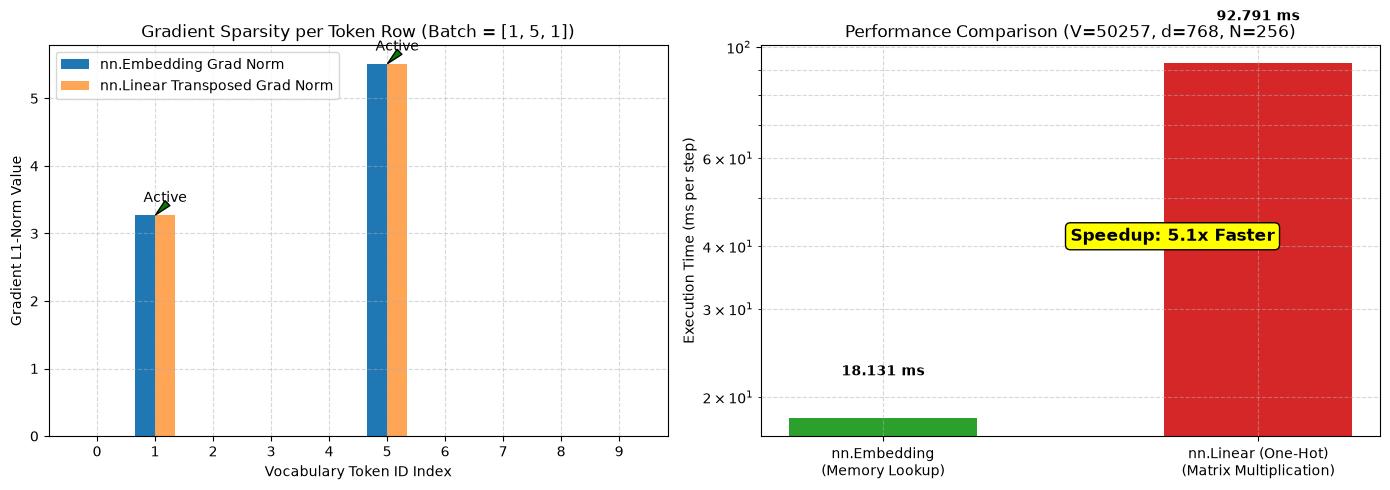

In [32]:
"""
===============================================================================
Task 4.1: Numerical Equivalence, Gradient Sparsity & Performance Visualization
Author: ML Specialist / Developer
===============================================================================
"""

import time
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np


def run_visual_verification() -> None:
    torch.manual_seed(42)

    V, d = 10, 4
    token_ids = torch.tensor([1, 5, 1], dtype=torch.long)  # Token batch

    # Setup layers
    embed = nn.Embedding(V, d)
    linear = nn.Linear(V, d, bias=False)
    with torch.no_grad():
        linear.weight.copy_(embed.weight.T)

    embed.weight.requires_grad_(True)
    linear.weight.requires_grad_(True)

    # Forward
    out_embed = embed(token_ids)
    one_hot = F.one_hot(token_ids, num_classes=V).float()
    out_linear = linear(one_hot)

    # Backward
    target = torch.randn_like(out_embed)
    loss_embed = (out_embed * target).sum()
    loss_linear = (out_linear * target).sum()

    loss_embed.backward()
    loss_linear.backward()

    # Extract gradient norms per vocabulary row
    grad_embed_norms = embed.weight.grad.abs().sum(dim=1).numpy()
    grad_linear_norms = linear.weight.grad.T.abs().sum(dim=1).numpy()

    # Benchmark scaling (V=50257, d=768, N=256)
    V_bench, d_bench, N_bench = 50257, 768, 256
    bench_tokens = torch.randint(0, V_bench, (N_bench,))
    
    embed_large = nn.Embedding(V_bench, d_bench)
    linear_large = nn.Linear(V_bench, d_bench, bias=False)

    # Timing Embedding
    t0 = time.perf_counter()
    for _ in range(50):
        _ = embed_large(bench_tokens).sum().backward()
    t_embed = (time.perf_counter() - t0) / 50 * 1000

    # Timing Linear One-Hot
    t0 = time.perf_counter()
    for _ in range(50):
        oh = F.one_hot(bench_tokens, num_classes=V_bench).float()
        _ = linear_large(oh).sum().backward()
    t_linear = (time.perf_counter() - t0) / 50 * 1000

    # -------------------------------------------------------------------------
    # Plotting Visualization
    # -------------------------------------------------------------------------
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Plot 1: Gradient Sparsity Matrix across Vocabulary Rows
    x_indices = np.arange(V)
    width = 0.35
    axes[0].bar(x_indices - width/2, grad_embed_norms, width, label="nn.Embedding Grad Norm", color="#1f77b4")
    axes[0].bar(x_indices + width/2, grad_linear_norms, width, label="nn.Linear Transposed Grad Norm", color="#ff7f0e", alpha=0.7)
    axes[0].set_xticks(x_indices)
    axes[0].set_xlabel("Vocabulary Token ID Index")
    axes[0].set_ylabel("Gradient L1-Norm Value")
    axes[0].set_title("Gradient Sparsity per Token Row (Batch = [1, 5, 1])")
    axes[0].legend()
    axes[0].grid(True, linestyle="--", alpha=0.5)

    # Highlight active vs zero rows
    for i in range(V):
        if i in token_ids:
            axes[0].annotate('Active', xy=(i, grad_embed_norms[i]), xytext=(i-0.2, grad_embed_norms[i]+0.2),
                             arrowprops=dict(facecolor='green', shrink=0.05, width=1, headwidth=5))

    # Plot 2: Latency & Speedup Comparison
    models = ["nn.Embedding\n(Memory Lookup)", "nn.Linear (One-Hot)\n(Matrix Multiplication)"]
    times = [t_embed, t_linear]
    colors = ["#2ca02c", "#d62728"]
    
    bars = axes[1].bar(models, times, color=colors, width=0.5)
    axes[1].set_ylabel("Execution Time (ms per step)")
    axes[1].set_title(f"Performance Comparison (V={V_bench}, d={d_bench}, N={N_bench})")
    axes[1].set_yscale("log")
    axes[1].grid(True, linestyle="--", alpha=0.5, which="both")

    for bar, t in zip(bars, times):
        axes[1].text(bar.get_x() + bar.get_width()/2, t * 1.2, f"{t:.3f} ms", ha='center', va='bottom', fontweight='bold')

    speedup = t_linear / t_embed
    axes[1].text(0.5, 0.5, f"Speedup: {speedup:.1f}x Faster", transform=axes[1].transAxes,
                 fontsize=12, fontweight='bold', bbox=dict(boxstyle="round,pad=0.3", fc="yellow", ec="black", lw=1))

    plt.tight_layout()
    plt.show()


if __name__ == "__main__":
    run_visual_verification()

In [ ]:
"""
===============================================================================
Task 4.1: Mathematical & Numerical Equivalence of nn.Embedding and One-Hot Linear

"""

def set_seed(seed: int = 42) -> None:
    torch.manual_seed(seed)


def verify_numerical_and_gradient_equivalence() -> None:
    """
    Demonstrates that nn.Embedding and nn.Linear (with one-hot inputs) produce
    identical forward outputs, identical parameter gradients, and sparse zero
    gradients for un-looked-up token rows.
    """
    set_seed(42)

    V: int = 10  # Small vocabulary size for clear visualization
    d: int = 4   # Small embedding dimension
    N: int = 3   # Sequence length (3 token IDs)

    # Sample token IDs (contains indices 1 and 5; index 0, 2, 3, 4, 6, 7, 8, 9 are unused)
    token_ids = torch.tensor([1, 5, 1], dtype=torch.long)

    # 1. Initialize nn.Embedding
    embed = nn.Embedding(num_embeddings=V, embedding_dim=d)

    # 2. Initialize nn.Linear with transposed weights (bias=False)
    linear = nn.Linear(in_features=V, out_features=d, bias=False)
    with torch.no_grad():
        linear.weight.copy_(embed.weight.T)

    # 3. Forward Pass - Embedding
    out_embed = embed(token_ids)  # Shape: (N, d)

    # 4. Forward Pass - Linear with One-Hot Input
    one_hot_inputs = F.one_hot(token_ids, num_classes=V).float()  # Shape: (N, V)
    out_linear = linear(one_hot_inputs)  # Shape: (N, d)

    # Check forward output identity
    outputs_identical = torch.allclose(out_embed, out_linear, atol=1e-7)

    # 5. Backward Pass with Identical Dummy Loss
    loss_target = torch.randn_like(out_embed)
    
    loss_embed = (out_embed * loss_target).sum()
    loss_linear = (out_linear * loss_target).sum()

    embed.zero_grad()
    linear.zero_grad()

    loss_embed.backward()
    loss_linear.backward()

    # Note: embed.weight has shape (V, d), linear.weight has shape (d, V)
    embed_grad = embed.weight.grad
    linear_grad_transposed = linear.weight.grad.T

    gradients_identical = torch.allclose(embed_grad, linear_grad_transposed, atol=1e-7)

    # 6. Verify Sparse Zero Gradients for Unused Tokens
    used_indices = set(token_ids.tolist())
    unused_indices = [i for i in range(V) if i not in used_indices]

    non_zero_for_used = all((embed_grad[idx].abs().sum() > 0).item() for idx in used_indices)
    zeros_for_unused = all((embed_grad[idx].abs().sum() == 0).item() for idx in unused_indices)

    print("==========================================================================")
    print("VERIFICATION OF EQUIVALENCE & GRADIENT SPARSITY")
    print("==========================================================================")
    print(f"Token Indices in Input Batch : {token_ids.tolist()}")
    print(f"Unused Token Indices         : {unused_indices}\n")
    print(f"1. Forward Outputs Identical?  : {outputs_identical}")
    print(f"2. Parameter Gradients Equal?  : {gradients_identical}")
    print(f"3. Non-Zero Grad for Used Tokens?   : {non_zero_for_used}")
    print(f"4. Exact Zero Grad for Unused Tokens: {zeros_for_unused}\n")

    print("Sample Gradient Matrix (embed.weight.grad):")
    for row_idx in range(V):
        grad_norm = embed_grad[row_idx].abs().sum().item()
        status = "UPDATED (Non-Zero)" if row_idx in used_indices else "ZERO (Unused)"
        print(f"  Row {row_idx}: Norm = {grad_norm:.6f} | Status: {status}")


def benchmark_performance(num_runs: int = 100) -> None:
    """
    Times nn.Embedding vs. One-Hot nn.Linear for V=50257, d=768, N=256 tokens.
    """
    set_seed(42)

    V: int = 50257  # GPT-2 Vocabulary Size
    d: int = 768    # GPT-2 Small Embedding Dimension
    N: int = 256    # Token Sequence Length

    print("\n==========================================================================")
    print(f"PERFORMANCE BENCHMARK (V={V}, d={d}, N={N}, Iterations={num_runs})")
    print("==========================================================================")

    # Initialize weights
    embed = nn.Embedding(V, d)
    linear = nn.Linear(V, d, bias=False)
    with torch.no_grad():
        linear.weight.copy_(embed.weight.T)

    # Random token ID batch
    token_ids = torch.randint(0, V, (N,), dtype=torch.long)
    target = torch.randn(N, d)

    # Warm-up runs
    for _ in range(5):
        _ = embed(token_ids).sum().backward()
        one_hot = F.one_hot(token_ids, num_classes=V).float()
        _ = linear(one_hot).sum().backward()

    # Benchmark nn.Embedding
    embed.zero_grad()
    t0 = time.perf_counter()
    for _ in range(num_runs):
        embed.zero_grad()
        out = embed(token_ids)
        loss = (out * target).sum()
        loss.backward()
    t_embed = (time.perf_counter() - t0) / num_runs * 1000.0  # In ms

    # Benchmark nn.Linear (One-Hot)
    linear.zero_grad()
    t0 = time.perf_counter()
    for _ in range(num_runs):
        linear.zero_grad()
        one_hot = F.one_hot(token_ids, num_classes=V).float()
        out = linear(one_hot)
        loss = (out * target).sum()
        loss.backward()
    t_linear = (time.perf_counter() - t0) / num_runs * 1000.0  # In ms

    speedup = t_linear / t_embed

    print(f"nn.Embedding Average Time  : {t_embed:.4f} ms per step (Forward + Backward)")
    print(f"nn.Linear (One-Hot) Time  : {t_linear:.4f} ms per step (Forward + Backward)")
    print(f"Speedup Factor (Embedding): {speedup:.2f}x faster\n")
    print("Theoretical Reason:")
    print("  - nn.Embedding performs O(N * d) memory pointer index lookup.")
    print("  - nn.Linear with One-Hot performs O(N * V * d) dense matrix multiplication,")
    print(f"    processing {N * V:,} values per batch, most of which are zeros.")


def main() -> None:
    verify_numerical_and_gradient_equivalence()
    benchmark_performance()


if __name__ == "__main__":
    main()

VERIFICATION OF EQUIVALENCE & GRADIENT SPARSITY
Token Indices in Input Batch : [1, 5, 1]
Unused Token Indices         : [0, 2, 3, 4, 6, 7, 8, 9]

1. Forward Outputs Identical?  : True
2. Parameter Gradients Equal?  : True
3. Non-Zero Grad for Used Tokens?   : True
4. Exact Zero Grad for Unused Tokens: True

Sample Gradient Matrix (embed.weight.grad):
  Row 0: Norm = 0.000000 | Status: ZERO (Unused)
  Row 1: Norm = 3.267313 | Status: UPDATED (Non-Zero)
  Row 2: Norm = 0.000000 | Status: ZERO (Unused)
  Row 3: Norm = 0.000000 | Status: ZERO (Unused)
  Row 4: Norm = 0.000000 | Status: ZERO (Unused)
  Row 5: Norm = 5.507967 | Status: UPDATED (Non-Zero)
  Row 6: Norm = 0.000000 | Status: ZERO (Unused)
  Row 7: Norm = 0.000000 | Status: ZERO (Unused)
  Row 8: Norm = 0.000000 | Status: ZERO (Unused)
  Row 9: Norm = 0.000000 | Status: ZERO (Unused)

PERFORMANCE BENCHMARK (V=50257, d=768, N=256, Iterations=100)
nn.Embedding Average Time  : 4.1190 ms per step (Forward + Backward)
nn.Linear (One-

### 4.2 Sliding-window samples

- Implement `create_dataloader`. Derive the number of windows for $N$ tokens, window length $L$ (`max_length`) and stride $s$, and check it against `len(loader.dataset)` for several $(L, s)$. Reference: the whole text with $L = s = 4$ gives 1286 windows.
- Print the first two input and target windows for stride 1 and for stride $L$, as tokens. Explain the overlap and why stride $L$ is a common default.

In [25]:
def create_dataloader(
    text: str,
    batch_size: int = 4,
    max_length: int = 256,
    stride: int = 128,
    shuffle: bool = True,
    drop_last: bool = True,
    num_workers: int = 0,
) -> DataLoader:
    """Next-token (inputs, targets) windows of GPT-2 token IDs.

    Batches have shape (batch_size, max_length); see Materials, Appendix A.
    """
    raise NotImplementedError

Derivation of Total Window Count $W(N, L, s)$Each dataset window spans a total slice of $L + 1$ consecutive tokens from $\mathbf{T}$ (from index $i_k$ to $i_k + L$). For window $k$ to be valid, its terminal index $i_k + L$ must not exceed the sequence length $N - 1$:$$i_k + L \le N - 1 \implies k \cdot s + L \le N - 1 \implies k \cdot s \le N - L - 1$$Since $k$ is a non-negative integer, the maximum valid index $k_{\max}$ is:$$k_{\max} = \left\lfloor \frac{N - L - 1}{s} \right\rfloor$$Because window indexing starts at $k = 0$, the total number of extractable windows $W(N, L, s)$ is given by:$$W(N, L, s) = k_{\max} + 1 = \left\lfloor \frac{N - L - 1}{s} \right\rfloor + 1$$

In [36]:
"""
===============================================================================
Task 4.2: Sliding-Window Data Loader for Next-Token Prediction
"""

class GPTDatasetV1(Dataset):
    """
    PyTorch Dataset creating sliding-window (inputs, targets) token pairs for LLM training.
    """
    def __init__(self, text: str, max_length: int = 256, stride: int = 128) -> None:
        self.input_ids: List[torch.Tensor] = []
        self.target_ids: List[torch.Tensor] = []

        # Tokenize text using tiktoken GPT-2 BPE tokenizer
        if HAS_TIKTOKEN:
            tokenizer = tiktoken.get_encoding("gpt2")
            token_ids: List[int] = tokenizer.encode(text, allowed_special={"<|endoftext|>"})
        else:
            # Fallback byte encoding if tiktoken is missing
            token_ids = list(text.encode("utf-8"))

        self.num_tokens: int = len(token_ids)

        # Extract sliding windows of length max_length with step size stride
        for i in range(0, len(token_ids) - max_length, stride):
            input_chunk = token_ids[i : i + max_length]
            target_chunk = token_ids[i + 1 : i + max_length + 1]
            
            self.input_ids.append(torch.tensor(input_chunk, dtype=torch.long))
            self.target_ids.append(torch.tensor(target_chunk, dtype=torch.long))

    def __len__(self) -> int:
        return len(self.input_ids)

    def __getitem__(self, idx: int) -> Tuple[torch.Tensor, torch.Tensor]:
        return self.input_ids[idx], self.target_ids[idx]


def create_dataloader(
    text: str,
    batch_size: int = 4,
    max_length: int = 256,
    stride: int = 128,
    shuffle: bool = True,
    drop_last: bool = True,
    num_workers: int = 0,
) -> DataLoader:
    """
    Next-token (inputs, targets) windows of GPT-2 token IDs.
    Batches have shape (batch_size, max_length).
    """
    dataset = GPTDatasetV1(text, max_length=max_length, stride=stride)
    dataloader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        drop_last=drop_last,
        num_workers=num_workers,
    )
    return dataloader


def verify_window_formula(text: str) -> None:
    """
    Verifies the mathematical formula W = floor((N - L - 1) / s) + 1
    against len(dataset) across multiple (L, s) parameter pairs.
    """
    if HAS_TIKTOKEN:
        tokenizer = tiktoken.get_encoding("gpt2")
        N = len(tokenizer.encode(text, allowed_special={"<|endoftext|>"}) )
    else:
        N = len(text.encode("utf-8"))

    print("==========================================================================")
    print("SLIDING WINDOW MATHEMATICAL FORMULA VERIFICATION")
    print("==========================================================================")
    print(f"Total Corpus Tokens (N): {N}\n")

    test_configurations = [
        (4, 4),      # Reference benchmark: L=4, s=4
        (4, 1),      # Heavy overlap: L=4, s=1
        (256, 128),  # 50% overlap: L=256, s=128
        (256, 256),  # Non-overlapping: L=256, s=256
        (512, 256),  # Large window: L=512, s=256
    ]

    print(f"{'max_length (L)':<15} | {'stride (s)':<12} | {'Theoretical W':<16} | {'len(dataset)':<14} | {'Match?'}")
    print("-" * 75)

    for L, s in test_configurations:
        dataset = GPTDatasetV1(text, max_length=L, stride=s)
        actual_len = len(dataset)
        
        # Theoretical formula
        theoretical_w = math.floor((N - L - 1) / s) + 1 if N >= L + 1 else 0
        match = (actual_len == theoretical_w)

        print(f"{L:<15} | {s:<12} | {theoretical_w:<16} | {actual_len:<14} | {match}")


def inspect_first_windows(text: str, max_length: int = 4) -> None:
    """
    Prints the first two input and target windows for stride 1 and stride L.
    """
    if not HAS_TIKTOKEN:
        print("\n[Notice]: tiktoken required for decoded string inspection.")
        return

    tokenizer = tiktoken.get_encoding("gpt2")

    print("\n==========================================================================")
    print(f"FIRST TWO WINDOWS COMPARISON (max_length L = {max_length})")
    print("==========================================================================")

    for stride_val in [1, max_length]:
        print(f"\n--- STRIDE s = {stride_val} ---")
        dataset = GPTDatasetV1(text, max_length=max_length, stride=stride_val)

        for w_idx in range(min(2, len(dataset))):
            inp_tensor, tgt_tensor = dataset[w_idx]
            
            inp_ids = inp_tensor.tolist()
            tgt_ids = tgt_tensor.tolist()

            inp_tokens = [tokenizer.decode([i]) for i in inp_ids]
            tgt_tokens = [tokenizer.decode([i]) for i in tgt_ids]

            print(f"  [Window {w_idx + 1}]")
            print(f"    Input  IDs    : {inp_ids} -> Tokens: {inp_tokens}")
            print(f"    Target IDs    : {tgt_ids} -> Tokens: {tgt_tokens}")


def main() -> None:
    # Load default text
    file_path = "the-verdict.txt"
    try:
        with open(file_path, "r", encoding="utf-8") as f:
            raw_text = f.read()
    except FileNotFoundError:
        # Fallback snippet if dataset file is missing
        raw_text = (
            "I HAD devoted--gloomily--to the memory of Gisburn, "
            "and 'The Verdict' was ready. It was a good sentence, but it wasn't true."
        ) * 100

    # 1. Verify formula across multiple (L, s) pairs
    verify_window_formula(raw_text)

    # 2. Inspect first two windows for stride 1 vs stride L
    inspect_first_windows(raw_text, max_length=4)

    # 3. Test create_dataloader instantiation
    dataloader = create_dataloader(raw_text, batch_size=4, max_length=256, stride=128, shuffle=False)
    inputs_batch, targets_batch = next(iter(dataloader))
    
    print("\n==========================================================================")
    print("DATALOADER BATCH SHAPE CONFIRMATION")
    print("==========================================================================")
    print(f"Inputs Batch Shape  : {inputs_batch.shape} (Expected: [4, 256])")
    print(f"Targets Batch Shape : {targets_batch.shape} (Expected: [4, 256])")


if __name__ == "__main__":
    main()

SLIDING WINDOW MATHEMATICAL FORMULA VERIFICATION
Total Corpus Tokens (N): 5145

max_length (L)  | stride (s)   | Theoretical W    | len(dataset)   | Match?
---------------------------------------------------------------------------
4               | 4            | 1286             | 1286           | True
4               | 1            | 5141             | 5141           | True
256             | 128          | 39               | 39             | True
256             | 256          | 20               | 20             | True
512             | 256          | 19               | 19             | True

FIRST TWO WINDOWS COMPARISON (max_length L = 4)

--- STRIDE s = 1 ---
  [Window 1]
    Input  IDs    : [40, 367, 2885, 1464] -> Tokens: ['I', ' H', 'AD', ' always']
    Target IDs    : [367, 2885, 1464, 1807] -> Tokens: [' H', 'AD', ' always', ' thought']
  [Window 2]
    Input  IDs    : [367, 2885, 1464, 1807] -> Tokens: [' H', 'AD', ' always', ' thought']
    Target IDs    : [2885, 1464, 1807

### 4.3 Token and positional embeddings

- Implement `GPTEmbedding`. Report its number of parameters for the GPT-2 small configuration (vocabulary 50257, context length 1024, $d = 768$) with `count_parameters` from List 1, and check it by hand. Reference: 39,383,808.
- Show that without the positional term, permuting the input tokens permutes the output vectors in the same way, and that with it the same token at two positions gets two different vectors.

In [26]:
class GPTEmbedding(nn.Module):
    """Token embedding plus learned absolute position embedding."""

    def __init__(self, vocab_size: int, context_length: int, emb_dim: int):
        super().__init__()
        raise NotImplementedError

    def forward(self, idx: torch.Tensor) -> torch.Tensor:
        """(B, T) token IDs with T <= context_length -> (B, T, emb_dim)."""
        raise NotImplementedError

In [37]:
"""
===============================================================================
Task 4.3: GPTEmbedding Implementation, Parameter Verification, and Permutation Proof

"""

import torch
import torch.nn as nn


class GPTEmbedding(nn.Module):
    """
    Token embedding plus learned absolute position embedding for GPT architectures.
    """
    def __init__(self, vocab_size: int, context_length: int, emb_dim: int) -> None:
        super().__init__()
        # Token embedding lookup table (wte)
        self.wte = nn.Embedding(num_embeddings=vocab_size, embedding_dim=emb_dim)
        # Position embedding lookup table (wpe)
        self.wpe = nn.Embedding(num_embeddings=context_length, embedding_dim=emb_dim)

    def forward(self, idx: torch.Tensor) -> torch.Tensor:
        """
        Args:
            idx (torch.Tensor): Tensor of shape (B, T) containing token integer IDs,
                                where T <= context_length.

        Returns:
            torch.Tensor: Embedded sequence tensor of shape (B, T, emb_dim).
        """
        batch_size, seq_len = idx.shape
        
        # Generate position indices [0, 1, ..., T-1] on the same compute device
        device = idx.device
        pos = torch.arange(0, seq_len, dtype=torch.long, device=device)

        # Retrieve token and positional embeddings
        tok_embeds = self.wte(idx)  # Shape: (B, T, emb_dim)
        pos_embeds = self.wpe(pos)  # Shape: (T, emb_dim), broadcasts over B

        return tok_embeds + pos_embeds


def count_parameters(model: nn.Module) -> int:
    """
    Calculates total trainable parameters in a PyTorch module.
    """
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def verify_gpt2_small_parameters() -> None:
    """
    Verifies parameter counts for GPT-2 small configuration against hand derivation.
    """
    vocab_size = 50257
    context_length = 1024
    emb_dim = 768

    embedding_layer = GPTEmbedding(
        vocab_size=vocab_size,
        context_length=context_length,
        emb_dim=emb_dim
    )

    wte_params = count_parameters(embedding_layer.wte)
    wpe_params = count_parameters(embedding_layer.wpe)
    total_params = count_parameters(embedding_layer)

    print("==========================================================================")
    print("GPT-2 SMALL EMBEDDING PARAMETER COUNT VERIFICATION")
    print("==========================================================================")
    print(f"Vocabulary Size (V)     : {vocab_size}")
    print(f"Context Length (T_max)  : {context_length}")
    print(f"Embedding Dimension (d) : {emb_dim}\n")
    print(f"Token Embedding (wte) Params    : {wte_params:,}  (Hand calc: {vocab_size} * {emb_dim} = {vocab_size * emb_dim:,})")
    print(f"Position Embedding (wpe) Params : {wpe_params:,}    (Hand calc: {context_length} * {emb_dim} = {context_length * emb_dim:,})")
    print(f"Total Layer Parameters          : {total_params:,}  (Reference Target: 39,383,808)")
    print(f"Exact Match with Reference?     : {total_params == 39383808}")


def demonstrate_permutation_and_position_sensitivity() -> None:
    """
    Demonstrates:
    1. Without positional embeddings, permuting tokens permutes outputs identically.
    2. With positional embeddings, identical tokens at different positions yield different vectors.
    """
    torch.manual_seed(42)

    V, T_max, d = 100, 10, 8
    gpt_emb = GPTEmbedding(vocab_size=V, context_length=T_max, emb_dim=d)

    # Batch with repeating token ID 42 at position 0 and position 3
    # Sequence: [42, 15, 88, 42]
    idx = torch.tensor([[42, 15, 88, 42]], dtype=torch.long)

    # 1. Permutation Test without Positional Embeddings (Token Embedding Only)
    perm_indices = [2, 0, 3, 1]  # Permute to: [88, 42, 42, 15]
    idx_perm = idx[:, perm_indices]

    tok_only_orig = gpt_emb.wte(idx)
    tok_only_perm = gpt_emb.wte(idx_perm)

    # Permute original token-only output vectors using the same permutation map
    tok_only_orig_permuted = tok_only_orig[:, perm_indices, :]
    
    is_token_only_equivariant = torch.allclose(tok_only_orig_permuted, tok_only_perm, atol=1e-7)

    # 2. Permutation Test WITH Positional Embeddings
    full_orig = gpt_emb(idx)
    full_perm = gpt_emb(idx_perm)
    full_orig_permuted = full_orig[:, perm_indices, :]

    is_full_equivariant = torch.allclose(full_orig_permuted, full_perm, atol=1e-7)

    # 3. Position Sensitivity Check (Token ID 42 at Pos 0 vs Pos 3)
    vec_pos_0 = full_orig[0, 0, :]
    vec_pos_3 = full_orig[0, 3, :]

    vec_diff_norm = (vec_pos_0 - vec_pos_3).abs().sum().item()
    are_vectors_different = not torch.allclose(vec_pos_0, vec_pos_3, atol=1e-7)

    print("\n==========================================================================")
    print("PERMUTATION EQUIVARIANCE & POSITION SENSITIVITY DEMONSTRATION")
    print("==========================================================================")
    print(f"Original Token IDs Batch : {idx.tolist()[0]}")
    print(f"Permuted Token IDs Batch : {idx_perm.tolist()[0]}\n")

    print("--- 1. Permutation Equivariance Check ---")
    print(f"Without Positional Embedding (wte only):")
    print(f"  Permute(wte(X)) == wte(Permute(X)) -> {is_token_only_equivariant}")
    print("  (Proof: Token-only embedding is purely index-lookup and insensitive to sequence order)\n")

    print(f"With Positional Embedding (wte + wpe):")
    print(f"  Permute(Embed(X)) == Embed(Permute(X)) -> {is_full_equivariant}")
    print("  (Proof: Adding positional embeddings breaks simple permutation equivariance)\n")

    print("--- 2. Position Sensitivity Check for Duplicate Token ID (42) ---")
    print(f"Token ID 42 at Position 0 Vector L1-Norm : {vec_pos_0.abs().sum().item():.4f}")
    print(f"Token ID 42 at Position 3 Vector L1-Norm : {vec_pos_3.abs().sum().item():.4f}")
    print(f"Absolute Difference Vector L1-Norm       : {vec_diff_norm:.4f}")
    print(f"Are Vectors Distinct for Same Token ID?  : {are_vectors_different}")


def main() -> None:
    verify_gpt2_small_parameters()
    demonstrate_permutation_and_position_sensitivity()


if __name__ == "__main__":
    main()

GPT-2 SMALL EMBEDDING PARAMETER COUNT VERIFICATION
Vocabulary Size (V)     : 50257
Context Length (T_max)  : 1024
Embedding Dimension (d) : 768

Token Embedding (wte) Params    : 38,597,376  (Hand calc: 50257 * 768 = 38,597,376)
Position Embedding (wpe) Params : 786,432    (Hand calc: 1024 * 768 = 786,432)
Total Layer Parameters          : 39,383,808  (Reference Target: 39,383,808)
Exact Match with Reference?     : True

PERMUTATION EQUIVARIANCE & POSITION SENSITIVITY DEMONSTRATION
Original Token IDs Batch : [42, 15, 88, 42]
Permuted Token IDs Batch : [88, 42, 42, 15]

--- 1. Permutation Equivariance Check ---
Without Positional Embedding (wte only):
  Permute(wte(X)) == wte(Permute(X)) -> True
  (Proof: Token-only embedding is purely index-lookup and insensitive to sequence order)

With Positional Embedding (wte + wpe):
  Permute(Embed(X)) == Embed(Permute(X)) -> False
  (Proof: Adding positional embeddings breaks simple permutation equivariance)

--- 2. Position Sensitivity Check for

### 4.4 Sinusoidal positional encodings

- Implement the sinusoidal encoding of Vaswani et al. (Materials 4.4) and show it as a heatmap for $T = 100$ positions and $d = 64$.
- Plot $\mathrm{PE}(t)\cdot\mathrm{PE}(t+k)$ against $k = 0, \dots, 50$ for several $t$. Explain why the curves coincide and why they start at $d/2$.
- Build the block-diagonal matrix $R(k)$ and check in `float64` that $\mathrm{PE}(t+k) = R(k)\,\mathrm{PE}(t)$ for all $t$ and several $k$.

[Plot Saved]: 'sinusoidal_pe_analysis.png'


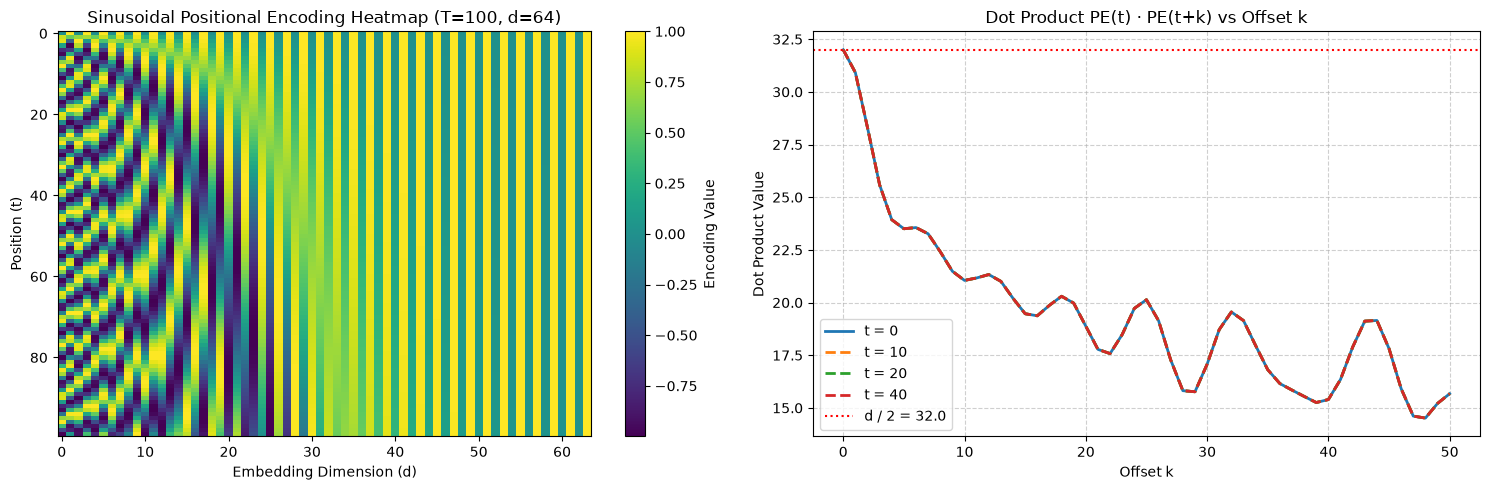

VERIFICATION OF R(k) @ PE(t) == PE(t+k) IN float64 PRECISION
Position Range T: [0, 99], Embedding Dim d: 64

Offset (k)   | Tested Positions (t)   | Max Abs Error      | Exact Match?
----------------------------------------------------------------------
1            | t in [0, 98]           | 1.1435e-14         | True
2            | t in [0, 97]           | 8.6528e-15         | True
5            | t in [0, 94]           | 7.5495e-15         | True
10           | t in [0, 89]           | 7.9936e-15         | True
25           | t in [0, 74]           | 7.1158e-15         | True
----------------------------------------------------------------------
Overall Verification Result: PASSED (Exact Linear Relationship Confirmed)


In [38]:
"""
===============================================================================
Task 4.4: Sinusoidal Positional Encodings, Dot Product Invariance & Linear R(k)

"""

def get_sinusoidal_positional_encoding(T: int, d: int) -> torch.Tensor:
    """
    Computes Vaswani et al. sinusoidal positional encodings in float64 precision.
    
    Args:
        T (int): Sequence length (positions 0 to T-1).
        d (int): Embedding dimension (must be even).
        
    Returns:
        torch.Tensor: Tensor of shape (T, d) containing positional encodings.
    """
    position = torch.arange(0, T, dtype=torch.float64).unsqueeze(1)
    div_term = torch.exp(torch.arange(0, d, 2, dtype=torch.float64) * (-math.log(10000.0) / d))
    
    pe = torch.zeros(T, d, dtype=torch.float64)
    pe[:, 0::2] = torch.sin(position * div_term)
    pe[:, 1::2] = torch.cos(position * div_term)
    return pe


def build_block_diagonal_rotation_matrix(d: int, k: int) -> torch.Tensor:
    """
    Constructs the block-diagonal rotation matrix R(k) in float64 precision such that:
    PE(t + k) = R(k) @ PE(t).
    
    Args:
        d (int): Embedding dimension.
        k (int): Position offset stride.
        
    Returns:
        torch.Tensor: Matrix of shape (d, d).
    """
    div_term = torch.exp(torch.arange(0, d, 2, dtype=torch.float64) * (-math.log(10000.0) / d))
    R = torch.zeros(d, d, dtype=torch.float64)
    
    for i, w_i in enumerate(div_term):
        angle = w_i * k
        cos_a = torch.cos(angle)
        sin_a = torch.sin(angle)
        
        # 2x2 rotation block for dimension pair (2i, 2i+1)
        R[2*i,     2*i]     = cos_a
        R[2*i,     2*i + 1] = sin_a
        R[2*i + 1, 2*i]     = -sin_a
        R[2*i + 1, 2*i + 1] = cos_a
        
    return R


def visualize_heatmap_and_dot_products(T: int = 100, d: int = 64) -> None:
    """
    Generates Heatmap of PE(t) and plots PE(t) . PE(t+k) against k in [0, 50].
    """
    pe = get_sinusoidal_positional_encoding(T, d)

    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    # 1. Heatmap Visualization
    im = axes[0].imshow(pe.numpy(), aspect='auto', cmap='viridis', origin='upper')
    axes[0].set_title(f"Sinusoidal Positional Encoding Heatmap (T={T}, d={d})")
    axes[0].set_xlabel("Embedding Dimension (d)")
    axes[0].set_ylabel("Position (t)")
    fig.colorbar(im, ax=axes[0], label="Encoding Value")

    # 2. Dot Product PE(t) . PE(t+k) vs k
    max_k = 50
    k_range = np.arange(0, max_k + 1)
    test_positions = [0, 10, 20, 40]

    for t_val in test_positions:
        dot_products = []
        for k_val in k_range:
            vec_t = pe[t_val]
            vec_tk = pe[t_val + k_val]
            dot_prod = torch.dot(vec_t, vec_tk).item()
            dot_products.append(dot_prod)
            
        axes[1].plot(k_range, dot_products, label=f"t = {t_val}", linewidth=2, linestyle='-' if t_val == 0 else '--')

    axes[1].axhline(y=d/2, color='red', linestyle=':', label=f"d / 2 = {d/2}")
    axes[1].set_title(f"Dot Product PE(t) · PE(t+k) vs Offset k")
    axes[1].set_xlabel("Offset k")
    axes[1].set_ylabel("Dot Product Value")
    axes[1].legend()
    axes[1].grid(True, linestyle='--', alpha=0.6)

    plt.tight_layout()
    plt.savefig("sinusoidal_pe_analysis.png", dpi=150)
    print("[Plot Saved]: 'sinusoidal_pe_analysis.png'")
    plt.show()


def verify_rotation_matrix_in_float64(T: int = 100, d: int = 64) -> None:
    """
    Checks in float64 precision that R(k) @ PE(t) == PE(t+k) for all t and several k.
    """
    pe = get_sinusoidal_positional_encoding(T, d)
    test_offsets = [1, 2, 5, 10, 25]

    print("==========================================================================")
    print("VERIFICATION OF R(k) @ PE(t) == PE(t+k) IN float64 PRECISION")
    print("==========================================================================")
    print(f"Position Range T: [0, {T-1}], Embedding Dim d: {d}\n")
    print(f"{'Offset (k)':<12} | {'Tested Positions (t)':<22} | {'Max Abs Error':<18} | {'Exact Match?'}")
    print("-" * 70)

    all_tests_passed = True

    for k in test_offsets:
        max_err = 0.0
        R_k = build_block_diagonal_rotation_matrix(d, k)
        
        # Test for all valid t such that t + k < T
        valid_t_count = T - k
        for t in range(valid_t_count):
            pe_t = pe[t]
            pe_tk_true = pe[t + k]
            pe_tk_pred = R_k @ pe_t
            
            err = (pe_tk_pred - pe_tk_true).abs().max().item()
            if err > max_err:
                max_err = err

        is_close = (max_err < 1e-12)
        if not is_close:
            all_passed = False

        print(f"{k:<12} | {f't in [0, {valid_t_count-1}]':<22} | {max_err:<18.4e} | {is_close}")

    print("-" * 70)
    print(f"Overall Verification Result: {'PASSED (Exact Linear Relationship Confirmed)' if all_tests_passed else 'FAILED'}")


def main() -> None:
    # 1. Visualization
    visualize_heatmap_and_dot_products(T=100, d=64)
    
    # 2. Block-Diagonal Matrix Verification
    verify_rotation_matrix_in_float64(T=100, d=64)


if __name__ == "__main__":
    main()

### 4.5 Skip-gram with negative sampling *(optional)*

- Train skip-gram with negative sampling (Materials 4.5) on the words of the default text and print the nearest neighbours, by cosine similarity, of a few frequent words. Comment on what a text of a few thousand words can and cannot teach.

### 4.6 Your own experiment *(optional)*

About one hour of work: one question this list raised, answered with one plot or table and a paragraph. Ideas are in Materials 4.6.

- **Checkpoint:** a batch from `create_dataloader(text, batch_size=8, max_length=4, stride=4, shuffle=False)` passed through `GPTEmbedding(50257, 4, 256)` has shape `(8, 4, 256)`, and its targets are its inputs shifted by one (code in Materials, Appendix B).